<a href="https://colab.research.google.com/github/d3m1d0s/FoML_projects/blob/main/project_1/bankchurners_eda_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Fundamentals of Machine Learning, Project 1**

### Exploratory and Cluster Analysis: Credit Card Customers

Author: Demid Ostiakov (OST0059)  
Dataset: [Credit Card Customers (Kaggle)](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/d3m1d0s/FoML_projects/main/project_1/BankChurners.csv/BankChurners.csv"

df = pd.read_csv(DATA_URL)

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> First Look at the Data </font></h2>
</div>

Display the first and last 20 rows of the dataset.

In [3]:
# show all columns instead of hiding the middle ones
pd.set_option("display.max_columns", None)

display(df.head(20))

display(df.tail(20))

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998
5,713061558,Existing Customer,44,M,2,Graduate,Married,$40K - $60K,Blue,36,3,1,2,4010.0,1247,2763.0,1.376,1088,24,0.846,0.311,0.000055,0.99994
6,810347208,Existing Customer,51,M,4,Unknown,Married,$120K +,Gold,46,6,1,3,34516.0,2264,32252.0,1.975,1330,31,0.722,0.066,0.000123,0.99988
7,818906208,Existing Customer,32,M,0,High School,Unknown,$60K - $80K,Silver,27,2,2,2,29081.0,1396,27685.0,2.204,1538,36,0.714,0.048,0.000086,0.99991
8,710930508,Existing Customer,37,M,3,Uneducated,Single,$60K - $80K,Blue,36,5,2,0,22352.0,2517,19835.0,3.355,1350,24,1.182,0.113,0.000045,0.99996
9,719661558,Existing Customer,48,M,2,Graduate,Single,$80K - $120K,Blue,36,6,3,3,11656.0,1677,9979.0,1.524,1441,32,0.882,0.144,0.000303,0.99970


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
10107,713924283,Attrited Customer,61,M,0,Graduate,Single,$60K - $80K,Blue,54,2,1,4,11859.0,1644,10215.0,0.866,8930,79,0.837,0.139,0.992680,0.007320
10108,714471183,Attrited Customer,47,M,4,Graduate,Divorced,$80K - $120K,Blue,39,4,3,4,17504.0,476,17028.0,0.892,10468,66,0.737,0.027,0.998160,0.001844
10109,780613758,Existing Customer,47,M,5,High School,Single,Less than $40K,Blue,35,4,3,5,4165.0,0,4165.0,0.813,17093,111,0.820,0.000,0.000896,0.999100
10110,718225683,Existing Customer,56,M,1,Graduate,Single,$80K - $120K,Silver,49,5,2,2,34516.0,1091,33425.0,0.640,15274,108,0.714,0.032,0.000097,0.999900
10111,710734308,Existing Customer,49,M,1,Graduate,Single,$60K - $80K,Blue,40,6,3,3,6481.0,1569,4912.0,0.692,15937,119,0.803,0.242,0.000284,0.999720
10112,708564858,Attrited Customer,33,M,2,College,Married,$120K +,Gold,20,2,1,4,34516.0,0,34516.0,1.004,9338,73,0.622,0.000,0.994380,0.005620
10113,713733633,Attrited Customer,27,M,0,High School,Divorced,$60K - $80K,Blue,36,2,3,2,13303.0,2517,10786.0,0.929,10219,85,0.809,0.189,0.993380,0.006620
10114,720841533,Existing Customer,29,M,0,Graduate,Married,Less than $40K,Blue,15,3,1,5,4700.0,0,4700.0,0.617,14723,96,0.655,0.000,0.000235,0.999770
10115,712210458,Existing Customer,38,M,1,Uneducated,Single,$40K - $60K,Blue,36,2,3,2,5639.0,1558,4081.0,0.614,16628,109,0.946,0.276,0.000174,0.999830
10116,714109308,Existing Customer,46,M,5,College,Single,$80K - $120K,Blue,36,1,2,3,13187.0,2241,10946.0,0.689,15354,112,0.931,0.170,0.000192,0.999810


The first and last rows look quite different. Among the first 20 customers there is no closed account, while 10 of the last 20 are attrited. The rows are therefore not in random order, and the file seems to be sorted in some way. A few rows from one end of the file are not a representative sample, so conclusions should always be based on the whole dataset, and any sampling or splitting later on has to be random.

Each row describes one credit card customer of the bank: who they are (age, gender, education, income), which card they hold, and how they used it over the last 12 months.

Column descriptions, based on the dataset's Kaggle page:
- `CLIENTNUM`: unique customer ID.
- `Attrition_Flag`: whether the customer closed the account ("Attrited Customer") or is still active ("Existing Customer").
- `Customer_Age`: age in years.
- `Gender`: M or F.
- `Dependent_count`: number of dependents.
- `Education_Level`: educational qualification (Uneducated, High School, College, Graduate, Post-Graduate, Doctorate or Unknown).
- `Marital_Status`: Married, Single, Divorced or Unknown.
- `Income_Category`: annual income band, from "Less than \$40K" to "\$120K +", or Unknown.
- `Card_Category`: card type (Blue, Silver, Gold or Platinum).
- `Months_on_book`: how many months the customer has been with the bank.
- `Total_Relationship_Count`: number of bank products the customer holds.
- `Months_Inactive_12_mon`: number of months the customer was inactive in the last 12 months. The page does not define what counts as inactive.
- `Contacts_Count_12_mon`: number of contacts in the last 12 months. The page does not say who initiated them.
- `Credit_Limit`: credit limit on the card.
- `Total_Revolving_Bal`: balance carried over to the next month, i.e. the unpaid part of the debt.
- `Avg_Open_To_Buy`: credit still available to spend, averaged over the last 12 months.
- `Total_Amt_Chng_Q4_Q1`: total transaction amount in Q4 divided by the amount in Q1. Values below 1 mean the customer spent less in Q4 than in Q1.
- `Total_Trans_Amt`: total amount spent in the last 12 months.
- `Total_Trans_Ct`: number of transactions in the last 12 months.
- `Total_Ct_Chng_Q4_Q1`: number of transactions in Q4 divided by the number in Q1.
- `Avg_Utilization_Ratio`: average share of the credit limit the customer uses.
- `Naive_Bayes_Classifier_..._1` and `..._2`: described only as "Naive Bayes". According to their names, they are outputs of a Naive Bayes classifier for `Attrition_Flag`, so they are not customer data.

The target is `Attrition_Flag`. "Attrited Customer" means the customer closed the account, while "Existing Customer" means they stayed. In this project it is not used to build clusters, only to compare them later and see if some groups have more closed accounts than others.

Check the basic information about the DataFrame.

In [4]:
cut_df = df.rename(columns=lambda x: x[:30] + '...' if len(x) > 30 else x)

cut_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   CLIENTNUM                          10127 non-null  int64  
 1   Attrition_Flag                     10127 non-null  object 
 2   Customer_Age                       10127 non-null  int64  
 3   Gender                             10127 non-null  object 
 4   Dependent_count                    10127 non-null  int64  
 5   Education_Level                    10127 non-null  object 
 6   Marital_Status                     10127 non-null  object 
 7   Income_Category                    10127 non-null  object 
 8   Card_Category                      10127 non-null  object 
 9   Months_on_book                     10127 non-null  int64  
 10  Total_Relationship_Count           10127 non-null  int64  
 11  Months_Inactive_12_mon             10127 non-null  int

The dataset has 10,127 rows and 23 columns. According to `info()`, there are no missing values, as every column has 10,127 non-null entries. However, `head()` already shows the value "Unknown" in `Marital_Status` (row 3), so some missing information may be stored as text instead of NaN. This is checked later.

Some numerical columns are counts rather than continuous measurements. Judging by the first rows, they fall into two groups, and the exact number of values in each column is checked in the Variable Types section.
- `Dependent_count`, `Total_Relationship_Count`, `Months_Inactive_12_mon` and `Contacts_Count_12_mon` seem to take only a few small values. Each value then forms a large group of customers, so these columns are best explored value by value, with frequency tables (how many customers have each value) and bar charts.
- `Total_Trans_Ct` and `Months_on_book` seem to take many different values. A single value then contains only a few customers and neighbouring values hardly differ, so these columns are better treated as continuous and explored with histograms and quantiles.

Three columns are not real customer features and will be removed:
- `CLIENTNUM`, because it only identifies the customer. It is stored as `int64`, but its value carries no numerical meaning.
- The two `Naive_Bayes_Classifier_...` columns. They are the output of a classifier trained on `Attrition_Flag`, so they effectively contain the answer. The dataset author also recommends deleting them.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Duplicates and Column Cleanup </font></h2>
</div>

Before removing `CLIENTNUM`, we use it to check for duplicates. There are three basic cases:
- the same row appears more than once,
- the same customer ID appears more than once,
- two rows with different IDs contain exactly the same customer data.

In [5]:
full_row_dups = df.duplicated().sum()
id_dups = df["CLIENTNUM"].duplicated().sum()
data_dups = df.drop(columns=["CLIENTNUM"]).duplicated().sum()

print("Fully duplicated rows:", full_row_dups)
print("Duplicated customer IDs:", id_dups)
print("Duplicated rows ignoring the ID:", data_dups)

Fully duplicated rows: 0
Duplicated customer IDs: 0
Duplicated rows ignoring the ID: 0


The check confirmed that there are no duplicates of any kind in the dataset, so no further cleaning is required in this regard.

Now we remove the columns that are not real customer features: the ID and the two Naive Bayes columns.

In [6]:
nb_cols = [col for col in df.columns if col.startswith("Naive_Bayes")]

df = df.drop(columns=["CLIENTNUM"] + nb_cols)

print("Removed:", ["CLIENTNUM"] + nb_cols)
print("Shape after removal:", df.shape)

Removed: ['CLIENTNUM', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Shape after removal: (10127, 20)


After the removal, the dataset has 10,127 rows and 20 columns. One of them, `Attrition_Flag`, is the target. It stays in the dataset, but it will not be used as an input for clustering, only to describe the clusters afterwards. This leaves 19 columns that describe the customers themselves. Whether all of them are needed is not settled yet, since some may carry the same information as others.

Some columns may be calculated from other columns, and then they add no new information. Two candidates follow from the column descriptions. `Avg_Open_To_Buy` is the credit still available, which should be the limit minus the balance. `Avg_Utilization_Ratio` is the share of the limit in use, which should be the balance divided by the limit. Both relationships are checked on every row. The ratio is stored with three decimals, so it is compared with a tolerance of 0.0005.

In [7]:
open_to_buy_calc = df["Credit_Limit"] - df["Total_Revolving_Bal"]
utilization_calc = df["Total_Revolving_Bal"] / df["Credit_Limit"]

open_to_buy_match = np.isclose(df["Avg_Open_To_Buy"], open_to_buy_calc).sum()
utilization_match = np.isclose(df["Avg_Utilization_Ratio"], utilization_calc, atol=0.0005).sum()

print("Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal:", open_to_buy_match, "of", len(df), "rows")
print("Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit:", utilization_match, "of", len(df), "rows")

Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal: 10127 of 10127 rows
Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit: 10127 of 10127 rows


Both relationships hold for every customer, and despite the "Avg" in their names, neither column is an average over 12 months. Both are direct calculations from the limit and the balance.

`Avg_Open_To_Buy` is exactly the credit limit minus the revolving balance. It adds no information, and in clustering it would only give the limit and the balance extra weight in the distance between customers.

`Avg_Utilization_Ratio` is the balance divided by the limit. It is also fully determined by two columns we keep, so it is removed as well.

Both columns are still easy to read, for example "uses 70% of the limit" or "has 5,000 of credit left". They can be recomputed from `Credit_Limit` and `Total_Revolving_Bal` at any time, so they are brought back later wherever they are needed, at the latest in the final cluster profiles, where they help describe who the customers in each cluster are.

In [8]:
df = df.drop(columns=["Avg_Open_To_Buy", "Avg_Utilization_Ratio"])

print("Shape after removal:", df.shape)

Shape after removal: (10127, 18)


The dataset now has 18 columns: the target `Attrition_Flag` and 17 customer features.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Hidden Missing Values </font></h2>
</div>

According to `info()`, the dataset has no missing values, but the first rows already contain the value "Unknown". First we check how often it appears in each text column.

In [9]:
text_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]

unknown_counts = (df[text_cols] == "Unknown").sum()
display(unknown_counts)

,0
Attrition_Flag,0
Gender,0
Education_Level,1519
Marital_Status,749
Income_Category,1112
Card_Category,0


"Unknown" appears only in `Education_Level`, `Marital_Status` and `Income_Category`. The other text columns are complete.

In these three columns "Unknown" does not describe the customer. It only says that the bank does not have the information, so it is a missing value stored as text. As long as it stays a normal string, pandas counts it as an ordinary category, and it would also have to be placed somewhere in the natural order of education and income levels, where it does not belong. We therefore replace it with NaN, so that it is treated as missing.

In [10]:
df = df.replace("Unknown", np.nan)

In [11]:
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(1)
})
display(missing_summary[missing_summary["Missing count"] > 0])

rows_with_missing = df.isna().any(axis=1).sum()
print("Rows with at least one missing value:", rows_with_missing, f"({rows_with_missing / len(df) * 100:.1f}%)")

,Missing count,Missing percentage
Education_Level,1519,15.0
Marital_Status,749,7.4
Income_Category,1112,11.0


Rows with at least one missing value: 3046 (30.1%)


Education is missing for 15.0% of customers, income for 11.0% and marital status for 7.4%. Together, 3,046 customers (30.1%) have at least one missing value.

Removing incomplete rows would therefore cost almost a third of the dataset, and it could also bias the analysis if customers with missing information differ from the others. Removing whole columns is not justified either, because each of them is still known for most customers. How to handle the missing values in each column is decided later, after we have seen whether customers with missing information behave differently, for example whether they close their accounts more often.

Next we check whether the missing values fall on the same customers, for example because some records are incomplete as a whole. If the gaps in two columns are unrelated, the number of customers missing both is close to what chance alone would give: the share missing in the first column times the share missing in the second, times the number of customers.

In [12]:
from itertools import combinations

miss_cols = ["Education_Level", "Marital_Status", "Income_Category"]
missing_flags = df[miss_cols].isna()

display(missing_flags.sum(axis=1).value_counts().sort_index()
        .rename_axis("Missing values per customer").to_frame("Customers"))

pair_rows = []
for col_a, col_b in combinations(miss_cols, 2):
    pair_rows.append({
        "Columns": f"{col_a} + {col_b}",
        "Missing in both": (missing_flags[col_a] & missing_flags[col_b]).sum(),
        "Expected by chance": round(missing_flags[col_a].mean() * missing_flags[col_b].mean() * len(df))
    })

display(pd.DataFrame(pair_rows).set_index("Columns"))

,Customers
Missing values per customer,
0,7081
1,2719
2,320
3,7


,Missing in both,Expected by chance
Columns,,
Education_Level + Marital_Status,114,112
Education_Level + Income_Category,145,167
Marital_Status + Income_Category,82,82


Most incomplete customers miss only one value (2,719), 320 miss two and only 7 miss all three. For every pair of columns, the number of customers missing both is close to what chance would give (114 vs 112, 145 vs 167 and 82 vs 82). The gaps are therefore spread over the customers independently, and there is no group of generally incomplete records. Each column can be handled separately, and removing incomplete rows would make even less sense.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Variable Types </font></h2>
</div>

A pandas dtype only shows how the values are stored, not what they mean. Before any statistics or plots, each column is classified by its statistical type, because the type decides which summaries, plots and encodings make sense.

First, the numerical columns: how many different values each of them has and what range they cover.

In [13]:
num_cols = df.select_dtypes(include="number").columns

num_overview = pd.DataFrame({
    "Dtype": df[num_cols].dtypes,
    "Unique values": df[num_cols].nunique(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max()
})
display(num_overview)

,Dtype,Unique values,Min,Max
Customer_Age,int64,45,26.0,73.000
Dependent_count,int64,6,0.0,5.000
Months_on_book,int64,44,13.0,56.000
Total_Relationship_Count,int64,6,1.0,6.000
Months_Inactive_12_mon,int64,7,0.0,6.000
Contacts_Count_12_mon,int64,7,0.0,6.000
Credit_Limit,float64,6205,1438.3,34516.000
Total_Revolving_Bal,int64,1974,0.0,2517.000
Total_Amt_Chng_Q4_Q1,float64,1158,0.0,3.397
Total_Trans_Amt,int64,5033,510.0,18484.000


Four columns have only a handful of values: `Dependent_count` and `Total_Relationship_Count` have 6, `Months_Inactive_12_mon` and `Contacts_Count_12_mon` have 7. These are the small counts. `Customer_Age`, `Months_on_book` and `Total_Trans_Ct` are also whole numbers, but with 45, 44 and 126 different values. The remaining five columns are amounts and ratios with hundreds to thousands of different values, so they are clearly continuous.

The line between a count and a count treated as continuous is a rule of thumb of roughly 10 different values. Here every column is clearly on one side, with at most 7 or at least 44 values. The distinction only matters for exploring the data, not for clustering.

Together with the column descriptions, this gives the following classification:

| Variable | Pandas dtype | Statistical type |
| --- | --- | --- |
| `Attrition_Flag` | object | binary, target |
| `Customer_Age` | int64 | numerical, treated as continuous |
| `Gender` | object | nominal (binary) |
| `Dependent_count` | int64 | count (0 to 5) |
| `Education_Level` | object | ordinal |
| `Marital_Status` | object | nominal |
| `Income_Category` | object | ordinal (income bands) |
| `Card_Category` | object | ordinal (card tiers) |
| `Months_on_book` | int64 | count, treated as continuous |
| `Total_Relationship_Count` | int64 | count (1 to 6) |
| `Months_Inactive_12_mon` | int64 | count (0 to 6) |
| `Contacts_Count_12_mon` | int64 | count (0 to 6) |
| `Credit_Limit` | float64 | continuous |
| `Total_Revolving_Bal` | int64 | continuous |
| `Total_Amt_Chng_Q4_Q1` | float64 | continuous (ratio Q4 / Q1) |
| `Total_Trans_Amt` | int64 | continuous |
| `Total_Trans_Ct` | int64 | count, treated as continuous |
| `Total_Ct_Chng_Q4_Q1` | float64 | continuous (ratio Q4 / Q1) |

The text columns are checked the same way, with all their values and how often they occur. Missing values are shown as NaN.

In [14]:
for col in text_cols:
    display(df[col].value_counts(dropna=False))

,count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627


,count
Gender,
F,5358
M,4769


,count
Education_Level,
Graduate,3128
High School,2013
NaN,1519
Uneducated,1487
College,1013
Post-Graduate,516
Doctorate,451


,count
Marital_Status,
Married,4687
Single,3943
NaN,749
Divorced,748


,count
Income_Category,
Less than $40K,3561
$40K - $60K,1790
$80K - $120K,1535
$60K - $80K,1402
NaN,1112
$120K +,727


,count
Card_Category,
Blue,9436
Silver,555
Gold,116
Platinum,20


`Attrition_Flag` has two values and is the binary target. `Gender` (F and M) and `Marital_Status` (Married, Single and Divorced) have no natural order, so they are nominal. `Education_Level` (six levels from Uneducated to Doctorate), `Income_Category` (five income bands) and `Card_Category` (Blue, Silver, Gold and Platinum) do have a natural order, so they are ordinal. `Card_Category` is very unbalanced: 9,436 customers (93.2%) hold a Blue card and only 20 a Platinum card.

The numerical columns are already stored correctly. The text columns are all stored as plain `object`, which does not distinguish between nominal and ordinal variables, and the target is stored as text. These are converted next.

The target is replaced by a new column `Churned`, where 1 means the customer closed the account and 0 means they stayed. With this encoding, the mean of `Churned` in any group is directly the churn rate of that group.

In [15]:
df["Churned"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
df = df.drop(columns=["Attrition_Flag"])

df["Churned"].value_counts()

,count
Churned,
0,8500
1,1627


The ordinal columns get an explicit order, so that pandas sorts them and compares them by meaning and not alphabetically. The nominal columns become plain categories. Missing values remain NaN for now, because they are not part of any order.

In [16]:
education_order = ["Uneducated", "High School", "College", "Graduate", "Post-Graduate", "Doctorate"]
income_order = ["Less than $40K", "$40K - $60K", "$60K - $80K", "$80K - $120K", "$120K +"]
card_order = ["Blue", "Silver", "Gold", "Platinum"]

df["Education_Level"] = pd.Categorical(df["Education_Level"], categories=education_order, ordered=True)
df["Income_Category"] = pd.Categorical(df["Income_Category"], categories=income_order, ordered=True)
df["Card_Category"] = pd.Categorical(df["Card_Category"], categories=card_order, ordered=True)

df["Gender"] = df["Gender"].astype("category")
df["Marital_Status"] = df["Marital_Status"].astype("category")

A value that is not listed in the order would silently become NaN. To make sure nothing was lost, the missing counts must be the same as before the conversion (1,519, 749 and 1,112).

In [17]:
cat_cols = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]

display(df[cat_cols].isna().sum())
display(df.info())
print('Churned:', round(df['Churned'].mean(),3))

,0
Gender,0
Education_Level,1519
Marital_Status,749
Income_Category,1112
Card_Category,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Customer_Age              10127 non-null  int64   
 1   Gender                    10127 non-null  category
 2   Dependent_count           10127 non-null  int64   
 3   Education_Level           8608 non-null   category
 4   Marital_Status            9378 non-null   category
 5   Income_Category           9015 non-null   category
 6   Card_Category             10127 non-null  category
 7   Months_on_book            10127 non-null  int64   
 8   Total_Relationship_Count  10127 non-null  int64   
 9   Months_Inactive_12_mon    10127 non-null  int64   
 10  Contacts_Count_12_mon     10127 non-null  int64   
 11  Credit_Limit              10127 non-null  float64 
 12  Total_Revolving_Bal       10127 non-null  int64   
 13  Total_Amt_Chng_Q4_Q1      10127 non-null  floa

None

Churned: 0.161


`Churned` has 1,627 customers with value 1 and 8,500 with value 0, so 16.1% of the customers closed their account. The missing counts are unchanged, which means every known value matched one of the listed categories and the conversion lost nothing.

The dataset now consists of 12 numerical columns, 5 categorical columns (3 of them ordered) and the binary target `Churned`.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Univariate Analysis: Continuous Variables </font></h2>
</div>

This section looks at each continuous variable on its own: its centre, spread, shape and unusual values. The small counts and the categorical variables follow in a separate section.

In [18]:
cont_cols = ["Customer_Age", "Months_on_book", "Credit_Limit", "Total_Revolving_Bal",
             "Total_Amt_Chng_Q4_Q1", "Total_Trans_Amt", "Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1"]

### Descriptive statistics

Besides the usual summary, the table includes skewness. A value close to 0 means a roughly symmetric distribution, a positive value means a right-skewed distribution with a long right tail, and a negative value a left-skewed one with a long left tail.

In [19]:
cont_summary = df[cont_cols].describe().T
cont_summary["skew"] = df[cont_cols].skew()

display(cont_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skew
Customer_Age,10127.0,46.33,8.02,26.0,41.00,46.00,52.00,73.00,-0.03
Months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.00,56.00,-0.11
Credit_Limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.50,34516.00,1.67
Total_Revolving_Bal,10127.0,1162.81,814.99,0.0,359.00,1276.00,1784.00,2517.00,-0.15
Total_Amt_Chng_Q4_Q1,10127.0,0.76,0.22,0.0,0.63,0.74,0.86,3.40,1.73
Total_Trans_Amt,10127.0,4404.09,3397.13,510.0,2155.50,3899.00,4741.00,18484.00,2.04
Total_Trans_Ct,10127.0,64.86,23.47,10.0,45.00,67.00,81.00,139.00,0.15
Total_Ct_Chng_Q4_Q1,10127.0,0.71,0.24,0.0,0.58,0.70,0.82,3.71,2.06


Four variables are strongly right-skewed (skewness above 1.5): `Credit_Limit`, `Total_Trans_Amt`, `Total_Amt_Chng_Q4_Q1` and `Total_Ct_Chng_Q4_Q1`. For `Credit_Limit` the mean is almost twice the median (8,632 vs 4,549), and for `Total_Trans_Amt` it is also clearly higher (4,404 vs 3,899). For the two Q4/Q1 ratios the mean is only slightly above the median (0.76 vs 0.74 and 0.71 vs 0.70), even though their skewness is the highest. The reason is checked on the histograms.

`Customer_Age`, `Months_on_book` and `Total_Trans_Ct` look roughly symmetric, with skewness close to 0 and the mean close to the median. `Total_Revolving_Bal` also has a skewness close to 0, but its mean is below the median (1,163 vs 1,276), so its shape is checked on the histogram as well.

For the right-skewed variables, the median and the IQR describe a typical customer better than the mean and the standard deviation.

### Distributions

Histograms show the full shape of each distribution, which the summary table cannot. `Customer_Age`, `Months_on_book` and `Total_Trans_Ct` contain only whole numbers, so they get one bar per value. With a fixed number of bins, some bins would contain one whole number and others two, which creates spikes that do not exist in the data.

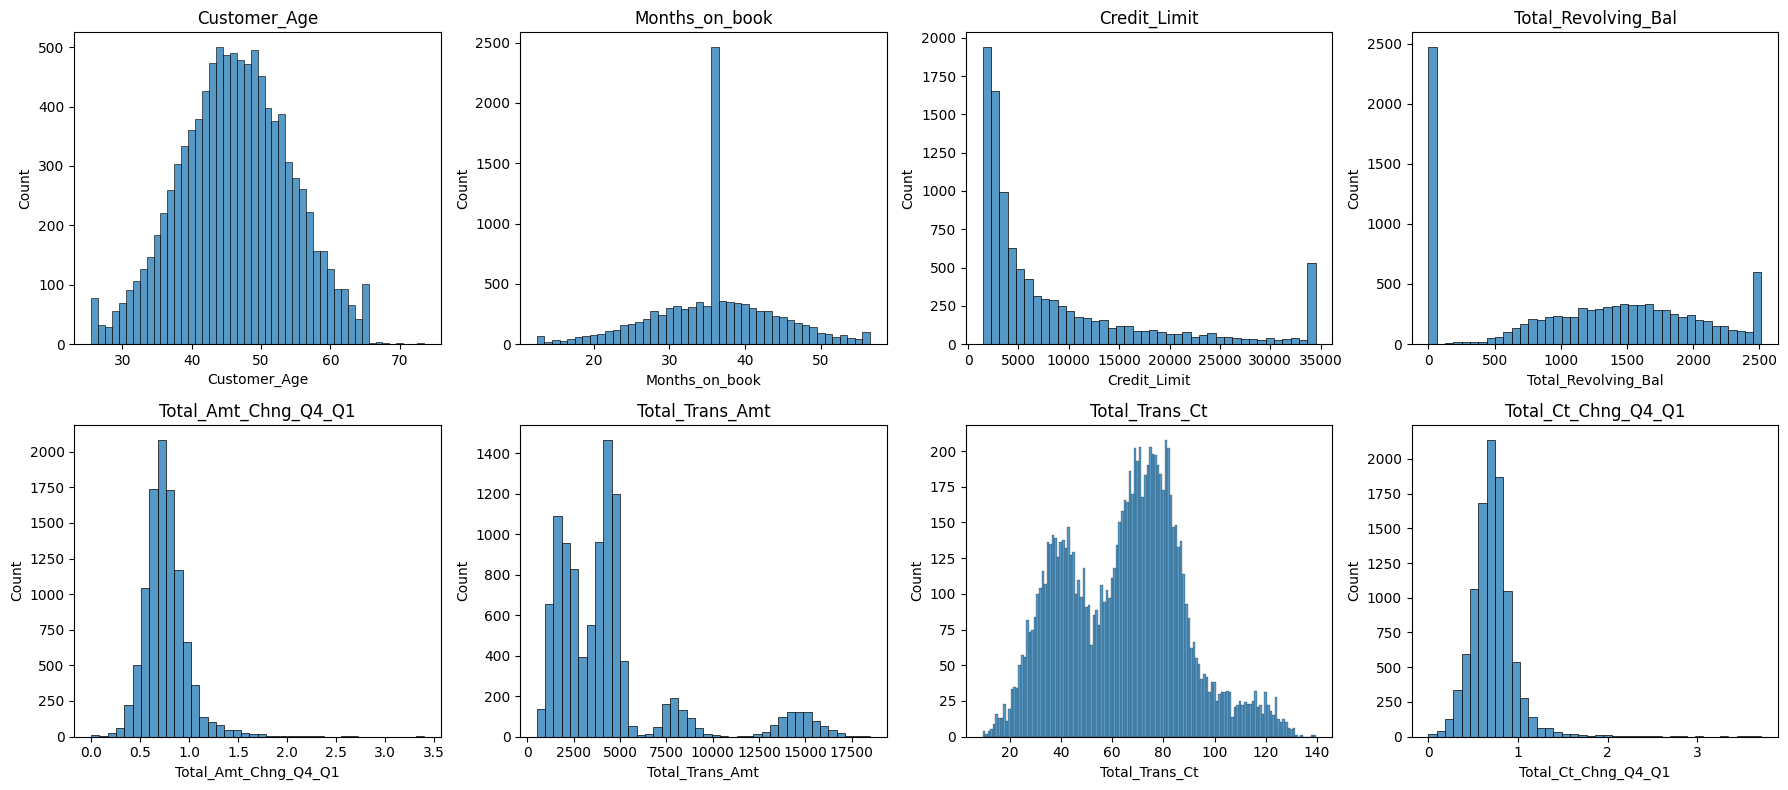

In [20]:
int_cols = ["Customer_Age", "Months_on_book", "Total_Trans_Ct"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, cont_cols):
    if col in int_cols:
        sns.histplot(data=df, x=col, discrete=True, ax=ax)
    else:
        sns.histplot(data=df, x=col, bins=40, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The histograms confirm the skewness for some variables, but they also show shapes that a single number cannot describe:
- `Customer_Age` is symmetric and bell-shaped.
- `Months_on_book` is roughly symmetric too, apart from one huge spike at around 36 months.
- `Total_Trans_Ct` is not a single bell, even though its skewness is close to 0. It has two peaks, one around 40 transactions and another around 70 to 80.
- `Credit_Limit` is right-skewed, with most customers at the lower end and a long tail, plus a separate pile at the maximum.
- `Total_Revolving_Bal` has three parts: a large group at zero, a bell-shaped middle part and a pile at the maximum. Its skewness is close to 0 only because these parts balance each other, and the group at zero explains why its mean is below the median.
- `Total_Amt_Chng_Q4_Q1` and `Total_Ct_Chng_Q4_Q1` have a narrow peak around 0.7 and a long, thin tail to the right. Only a few customers lie in the tail, so the mean barely moves, while the skewness reacts strongly.
- `Total_Trans_Amt` is right-skewed and has several separate groups: most customers spend less than about 5,500 (with two peaks of their own), a smaller group spends around 7,000 to 10,500, and another more than about 12,000.

Several of these patterns need an explanation:
- **The spike in `Months_on_book`:** about 2,500 customers have this single value, while its neighbours have only a few hundred each. A real wave of new customers would spread over several months, so this is more likely a default value used when the opening date was unknown, or a large one-time acquisition. The data cannot tell which, so the value is kept, but these customers are treated with caution.
- **Zero revolving balance:** about 2,500 customers carry no balance. In a credit card portfolio these are usually customers who pay their bill in full every month, or who barely use the card.
- **Piles at the maximum of `Credit_Limit` and `Total_Revolving_Bal`:** both have a separate bar at their highest value, much taller than the bars before it. A highest credit limit offered by the bank could explain the pile in `Credit_Limit`, but not the one in `Total_Revolving_Bal`, because a balance is already bounded by each customer's own credit limit. Smaller piles of the same kind appear at both ends of `Customer_Age` (near 26 and 65) and `Months_on_book` (13 and 56). The values were therefore most likely capped when the dataset was prepared, so everything above a certain boundary was replaced by the boundary itself. For the customers in these piles, the real value is unknown, only that it is at least as extreme as the boundary.
- **Groups in `Total_Trans_Amt` and two peaks in `Total_Trans_Ct`:** the customers seem to form distinct groups with low and high card activity. This is a first hint of natural groups for the cluster analysis, and the bivariate analysis will show whether churn differs between them.

The spike in `Months_on_book` and the group with zero revolving balance are both large. If they were mostly the same customers, both patterns could come from one source, for example accounts that were filled with default values. This is checked by comparing the two groups directly.

In [21]:
spike_36 = df["Months_on_book"] == 36
zero_balance = df["Total_Revolving_Bal"] == 0

overlap = pd.crosstab(
    spike_36.map({True: "36 months", False: "Other"}),
    zero_balance.map({True: "Zero balance", False: "Non-zero balance"}),
    margins=True,
    margins_name="Total"
)
overlap.index.name = None
overlap.columns.name = None
overlap["Zero balance (%)"] = (overlap["Zero balance"] / overlap["Total"] * 100).round(1)

display(overlap)

,Non-zero balance,Zero balance,Total,Zero balance (%)
36 months,1839,624,2463,25.3
Other,5818,1846,7664,24.1
Total,7657,2470,10127,24.4


Only 624 customers belong to both groups. Among the customers with 36 months, 25.3% have a zero balance, almost the same share as among all other customers (24.1%). The two patterns are therefore independent of each other and separate.

### Potential outliers

Boxplots summarise the median, the quartiles and the points outside the whiskers, which are 1.5 IQR below Q1 and above Q3.

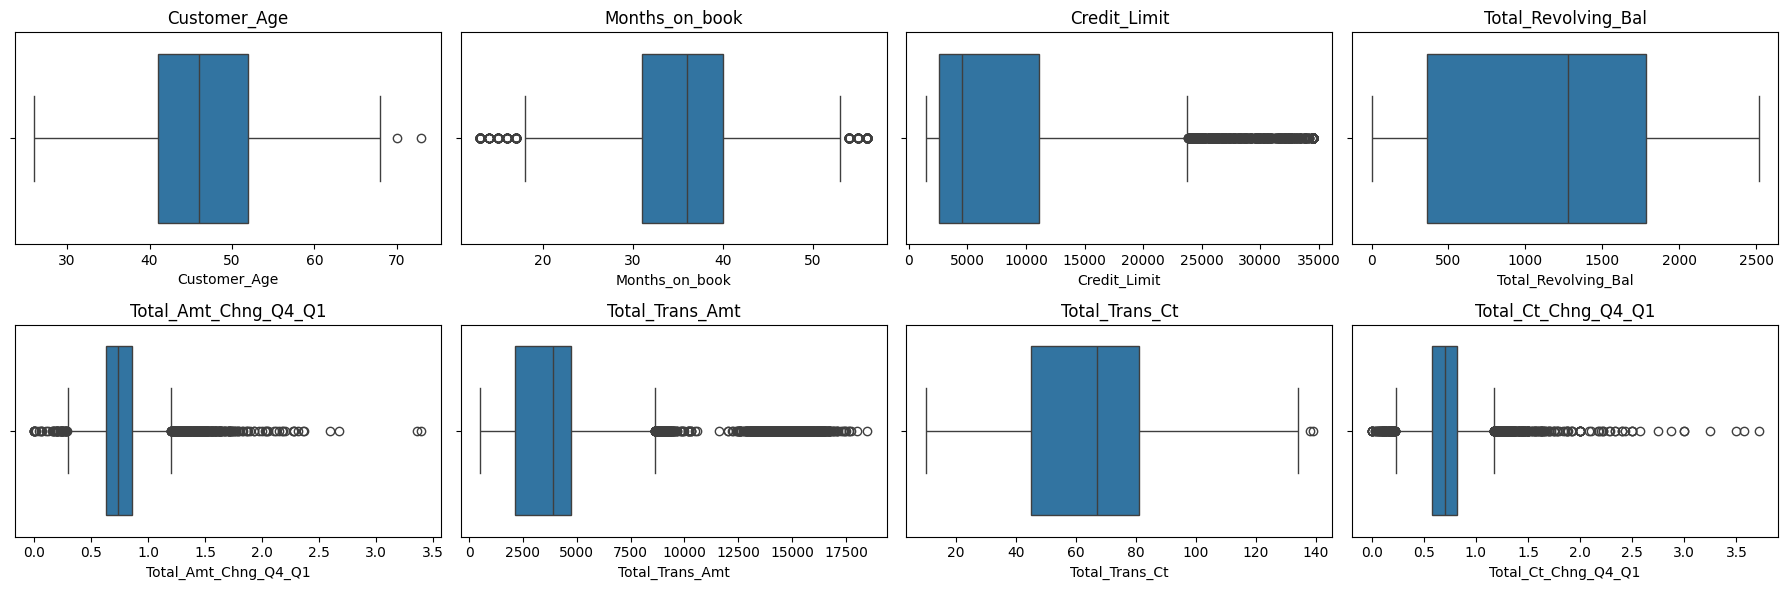

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))

for ax, col in zip(axes.flat, cont_cols):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The same IQR rule, counted for each variable:

In [23]:
outlier_rows = []

for col in cont_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    outlier_rows.append({
        "Variable": col,
        "Lower fence": lower_fence,
        "Upper fence": upper_fence,
        "Potential outliers": n_outliers,
        "Percentage": n_outliers / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("Variable")
display(outlier_summary.round(2))

,Lower fence,Upper fence,Potential outliers,Percentage
Variable,,,,
Customer_Age,24.50,68.50,2,0.02
Months_on_book,17.50,53.50,386,3.81
Credit_Limit,-10213.75,23836.25,984,9.72
Total_Revolving_Bal,-1778.50,3921.50,0,0.00
Total_Amt_Chng_Q4_Q1,0.29,1.20,396,3.91
Total_Trans_Amt,-1722.75,8619.25,896,8.85
Total_Trans_Ct,-9.00,135.00,2,0.02
Total_Ct_Chng_Q4_Q1,0.23,1.17,394,3.89


Most potential outliers are in `Credit_Limit` (984 customers, 9.72%) and `Total_Trans_Amt` (896, 8.85%), followed by the two Q4/Q1 ratios and `Months_on_book` with just under 4% each. `Customer_Age` and `Total_Trans_Ct` have only 2 each, and `Total_Revolving_Bal` has none.

Compared with the histograms, these are mostly not isolated points but whole parts of the distributions:
- `Credit_Limit`: the long right tail and the pile at the maximum.
- `Total_Trans_Amt`: the separate groups of customers who spend much more than the rest.
- The Q4/Q1 ratios: customers whose activity dropped sharply or grew strongly in Q4 compared with Q1. A sharp drop could come before closing an account.
- `Total_Revolving_Bal`: no outliers by the IQR rule, although its group at zero and the pile at the maximum are clearly unusual.

No values are removed, including the piles and the spike in `Months_on_book`, because they describe real groups of customers rather than mistakes. Whether the outliers are related to churn is checked in the bivariate analysis, and for the variables that enter the clustering, their influence on K-means is reduced by transforming them rather than by deleting customers.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Univariate Analysis: Counts and Categorical Variables </font></h2>
</div>

The small counts and the categorical variables have only a few values each, so they are explored value by value. Each bar shows the share of customers with that value, which makes variables with different numbers of values easy to compare. Missing values are added as a separate bar "Missing". Boxplots and the IQR rule are not used here. Categorical variables have no distances between their values, and for counts with only a few values the IQR rule would simply flag the lowest and highest values as outliers, although the bar charts already show exactly how rare they are.

In [24]:
def plot_shares(cols, figsize, rotation=0):
    fig, axes = plt.subplots(1, len(cols), figsize=figsize)

    for ax, col in zip(axes, cols):
        shares = df[col].value_counts().sort_index() / len(df) * 100
        # escape "$", otherwise matplotlib reads "$40K - $60K" as a formula
        shares.index = shares.index.astype(str).str.replace("$", r"\$", regex=False)
        if df[col].isna().any():
            shares["Missing"] = df[col].isna().mean() * 100

        bars = ax.bar(shares.index, shares.values)
        ax.bar_label(bars, fmt="%.1f")
        ax.margins(y=0.1)
        ax.set_title(col)
        ax.set_ylabel("Share of customers (%)")
        ax.tick_params(axis="x", rotation=rotation)

    plt.tight_layout()
    plt.show()

### Small counts

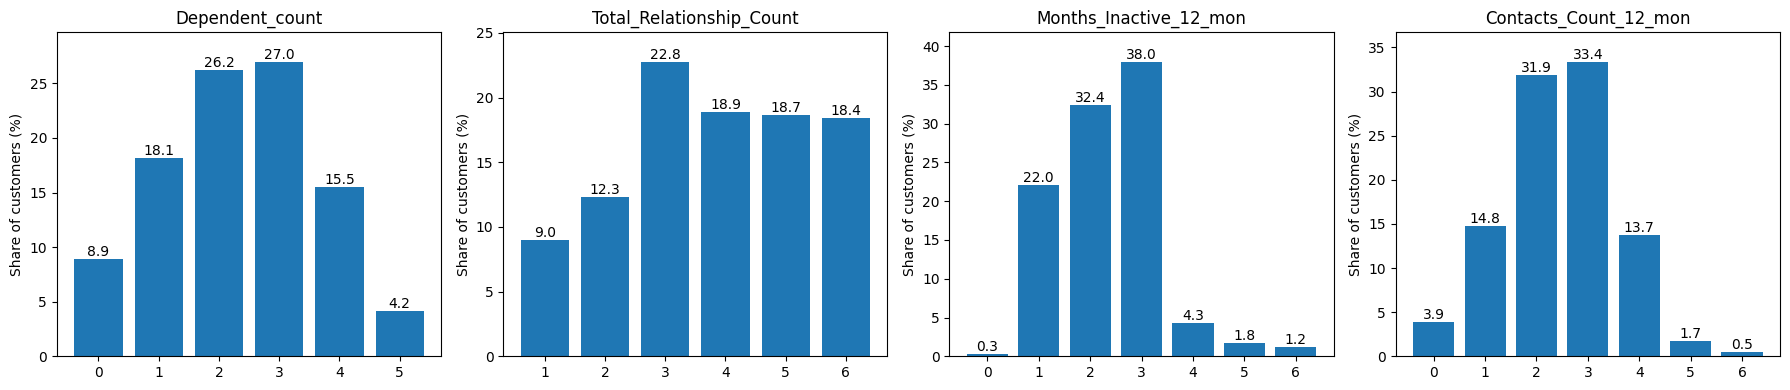

In [25]:
count_cols = ["Dependent_count", "Total_Relationship_Count", "Months_Inactive_12_mon", "Contacts_Count_12_mon"]

plot_shares(count_cols, figsize=(18, 4))

All four counts are concentrated on a few middle values:
- `Dependent_count`: most customers have 2 or 3 dependents (26.2% and 27.0%), while 0 and 5 are the rarest values.
- `Total_Relationship_Count`: 3 products is the most common value (22.8%), and 4, 5 and 6 products are almost equally common. Only 9.0% of the customers hold a single product, so most of them use several products of the bank.
- `Months_Inactive_12_mon`: almost all customers were inactive for 1 to 3 months (22.0%, 32.4% and 38.0%), and 4 or more months are rare.
- `Contacts_Count_12_mon`: 2 or 3 contacts per year are typical (31.9% and 33.4%), and 5 or 6 contacts are rare.

The most surprising value is 0 in `Months_Inactive_12_mon`: only 0.3% of the customers have no inactive month at all, although the median customer makes 67 transactions per year. The dataset description does not define what counts as an inactive month, so this cannot be explained further. Similarly, only 3.9% of the customers have no recorded contact in the last 12 months, and the description does not say whether these contacts come from the customer or from the bank.

### Categorical variables

The ordinal variables keep their natural order, and "Missing" is shown last.

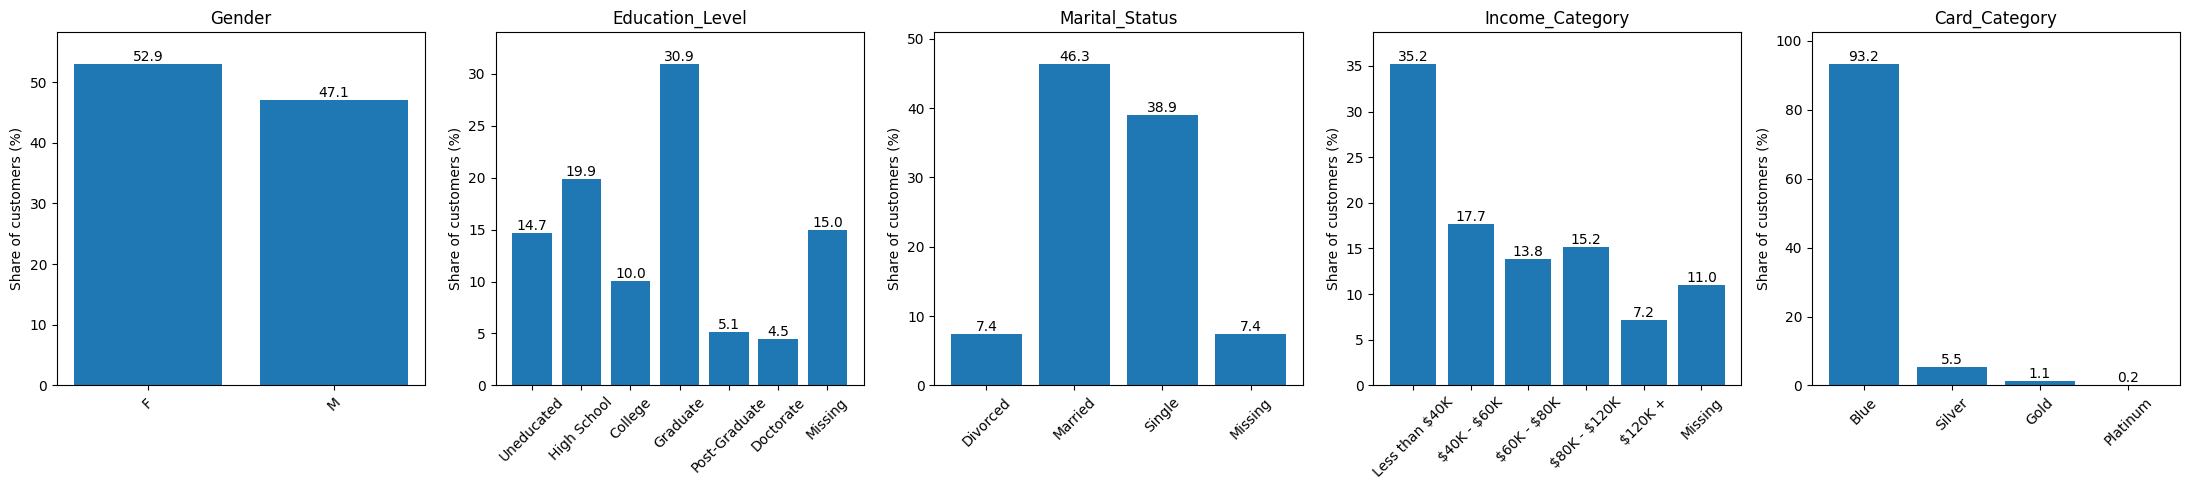

In [26]:
plot_shares(cat_cols, figsize=(22, 5), rotation=45)

`Gender` is almost balanced (52.9% women, 47.1% men). In the other variables a few categories dominate: Graduate in `Education_Level` (30.9%), Married and Single in `Marital_Status` (46.3% and 38.9%), and "Less than \$40K" in `Income_Category` (35.2%). Post-Graduate and Doctorate (5.1% and 4.5%), Divorced (7.4%) and "\$120K +" (7.2%) are small, but still large enough to be useful.

The "Missing" bars are as large as real categories. Missing education (15.0%) is bigger than College (10.0%) and about as big as Uneducated (14.7%), missing income (11.0%) is bigger than the highest income band, and missing marital status (7.4%) is as large as Divorced. The missing values therefore cannot be ignored, and how to handle them is decided after the churn comparison.

`Card_Category` is the real problem: 93.2% of the customers have a Blue card, and Gold and Platinum together make up only 1.3%. Such a variable carries very little information for clustering. After one-hot encoding, Platinum would become a column with only 20 customers, which could produce a tiny cluster of its own or simply add noise. A reasonable option is to merge the higher card tiers into one category, or to leave the variable out of the clustering and use it only to describe the clusters.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Bivariate Analysis: Churn by Counts and Categorical Variables </font></h2>
</div>

This section compares the churn rate between the values of each count and categorical variable. Because `Churned` is 1 for a closed account and 0 otherwise, the mean of `Churned` in a group is the share of customers in that group who closed their account.

Each bar shows the churn rate of one value together with the number of customers it is based on, and the dashed line marks the churn rate of all customers. Missing values are again a separate group "Missing", so that their churn rate can be compared with the known values.

In [27]:
overall_churn = df["Churned"].mean() * 100
print(f"Overall churn rate: {overall_churn:.1f}%")


def plot_churn_rates(cols, figsize, rotation=0):
    fig, axes = plt.subplots(1, len(cols), figsize=figsize)

    for ax, col in zip(axes, cols):
        groups = df.groupby(col, observed=False)["Churned"]
        rates = groups.mean() * 100
        sizes = groups.size()
        # escape "$", otherwise matplotlib reads "$40K - $60K" as a formula
        rates.index = rates.index.astype(str).str.replace("$", r"\$", regex=False)
        sizes.index = rates.index
        if df[col].isna().any():
            rates["Missing"] = df.loc[df[col].isna(), "Churned"].mean() * 100
            sizes["Missing"] = df[col].isna().sum()

        bars = ax.bar(rates.index, rates.values)
        ax.bar_label(bars, labels=[f"{rate:.1f}\n(n={size})" for rate, size in zip(rates, sizes)], fontsize=8)
        ax.axhline(overall_churn, color="gray", linestyle="--")
        ax.margins(y=0.2)
        ax.set_title(col)
        ax.set_ylabel("Churn rate (%)")
        ax.tick_params(axis="x", rotation=rotation)

    plt.tight_layout()
    plt.show()

Overall churn rate: 16.1%


### Small counts

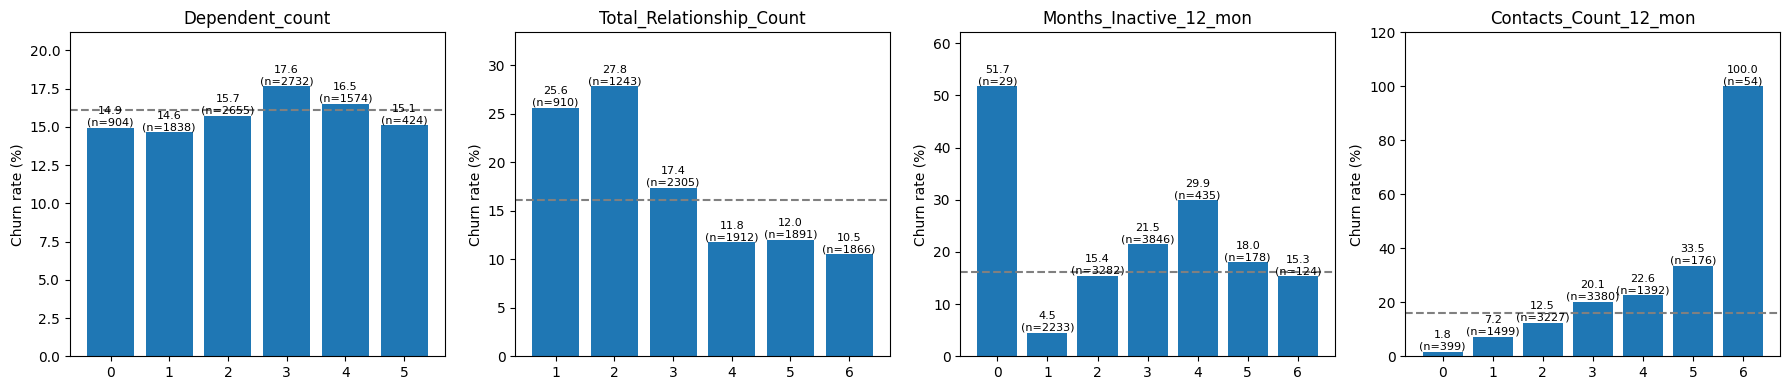

In [28]:
plot_churn_rates(count_cols, figsize=(18, 4))

Three of the four counts are clearly related to churn:
- `Total_Relationship_Count`: customers with 1 or 2 products churn much more often (25.6% and 27.8%) than customers with 4 to 6 products (10.5% to 12.0%). The more products a customer holds, the less likely they are to leave.
- `Contacts_Count_12_mon`: the churn rate rises steadily with the number of contacts, from 1.8% with no contact to 33.5% with 5 contacts, and all 54 customers with 6 contacts closed their account. The data cannot tell whether many contacts lead to churn or whether contacts made while leaving are also counted, so this variable describes the churn process at least as much as it predicts it.
- `Months_Inactive_12_mon`: the churn rate rises from 4.5% after 1 inactive month to 29.9% after 4 months. The values 5 and 6 break this trend, but they are based on only 178 and 124 customers.

`Dependent_count` shows no real effect: all its values lie between 14.6% and 17.6%, close to the overall rate.

The least reliable values are 0 inactive months (51.7%, but only 29 customers) and, to a lesser extent, 5 and 6 inactive months. The 100% for 6 contacts is also based on few customers (54), but a result this extreme is unlikely to be a coincidence.

### Categorical variables

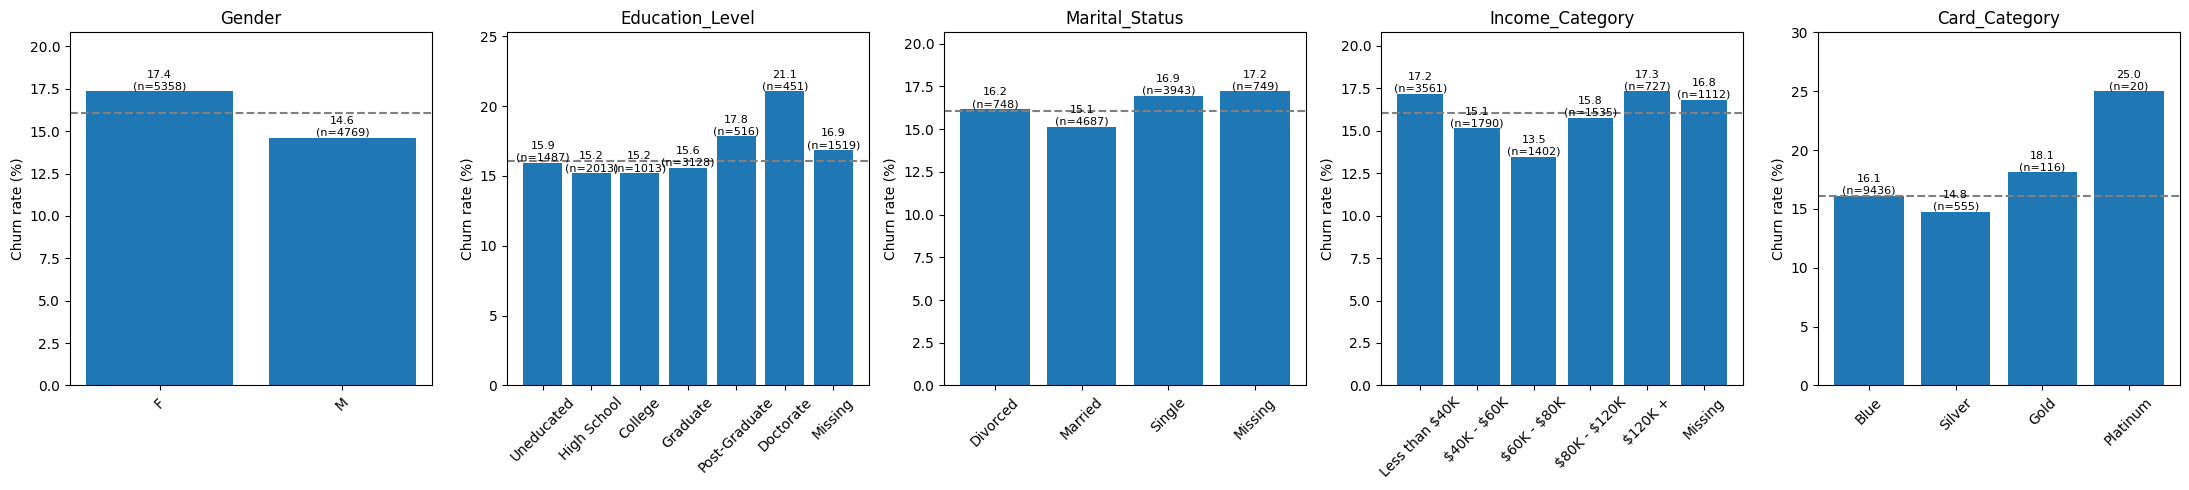

In [29]:
plot_churn_rates(cat_cols, figsize=(22, 5), rotation=45)

The categorical variables differ much less than the counts. Women churn slightly more often than men (17.4% vs 14.6%). In `Education_Level` the churn rate is close to average for most levels and higher only for Post-Graduate (17.8%) and Doctorate (21.1%). `Marital_Status` and `Income_Category` show no clear pattern: their rates lie between 13.5% and 17.3% and do not rise or fall with income. The demographic variables therefore say much less about churn than the behaviour of the customer.

The customers with missing values churn almost exactly like the others: 16.9% for missing education, 17.2% for missing marital status and 16.8% for missing income, all close to the overall rate of 16.1% and within the range of the known categories. Customers with a missing value therefore do not differ in their churn behaviour, and handling the missing values does not risk removing a churn signal.

The only categories too small to trust are the higher card tiers: Platinum (25.0%) is based on only 20 customers and Gold (18.1%) on 116. Their rates cannot be distinguished from the overall rate, which supports merging these tiers or leaving `Card_Category` out of the clustering.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Bivariate Analysis: Churn by Continuous Variables </font></h2>
</div>

This section compares the continuous variables between customers who stayed and customers who closed their account. Because most of these variables are skewed, the groups are compared by their medians rather than their means.

In [30]:
median_by_churn = df.groupby("Churned")[cont_cols].median().T
median_by_churn.columns = ["Stayed (0)", "Churned (1)"]

display(median_by_churn)

,Stayed (0),Churned (1)
Customer_Age,46.000,47.000
Months_on_book,36.000,36.000
Credit_Limit,4643.500,4178.000
Total_Revolving_Bal,1364.000,0.000
Total_Amt_Chng_Q4_Q1,0.743,0.701
Total_Trans_Amt,4100.000,2329.000
Total_Trans_Ct,71.000,43.000
Total_Ct_Chng_Q4_Q1,0.721,0.531


The medians show only the centre of each group, so the full distributions are compared as well. Only 16.1% of the customers churned, so with plain counts their histogram would be much lower than the other one and hard to compare. Each group is therefore scaled separately to the same total area (`stat="density"` with `common_norm=False`), which compares the shapes of the two groups, not their sizes. The whole-number variables again get one bar per value.

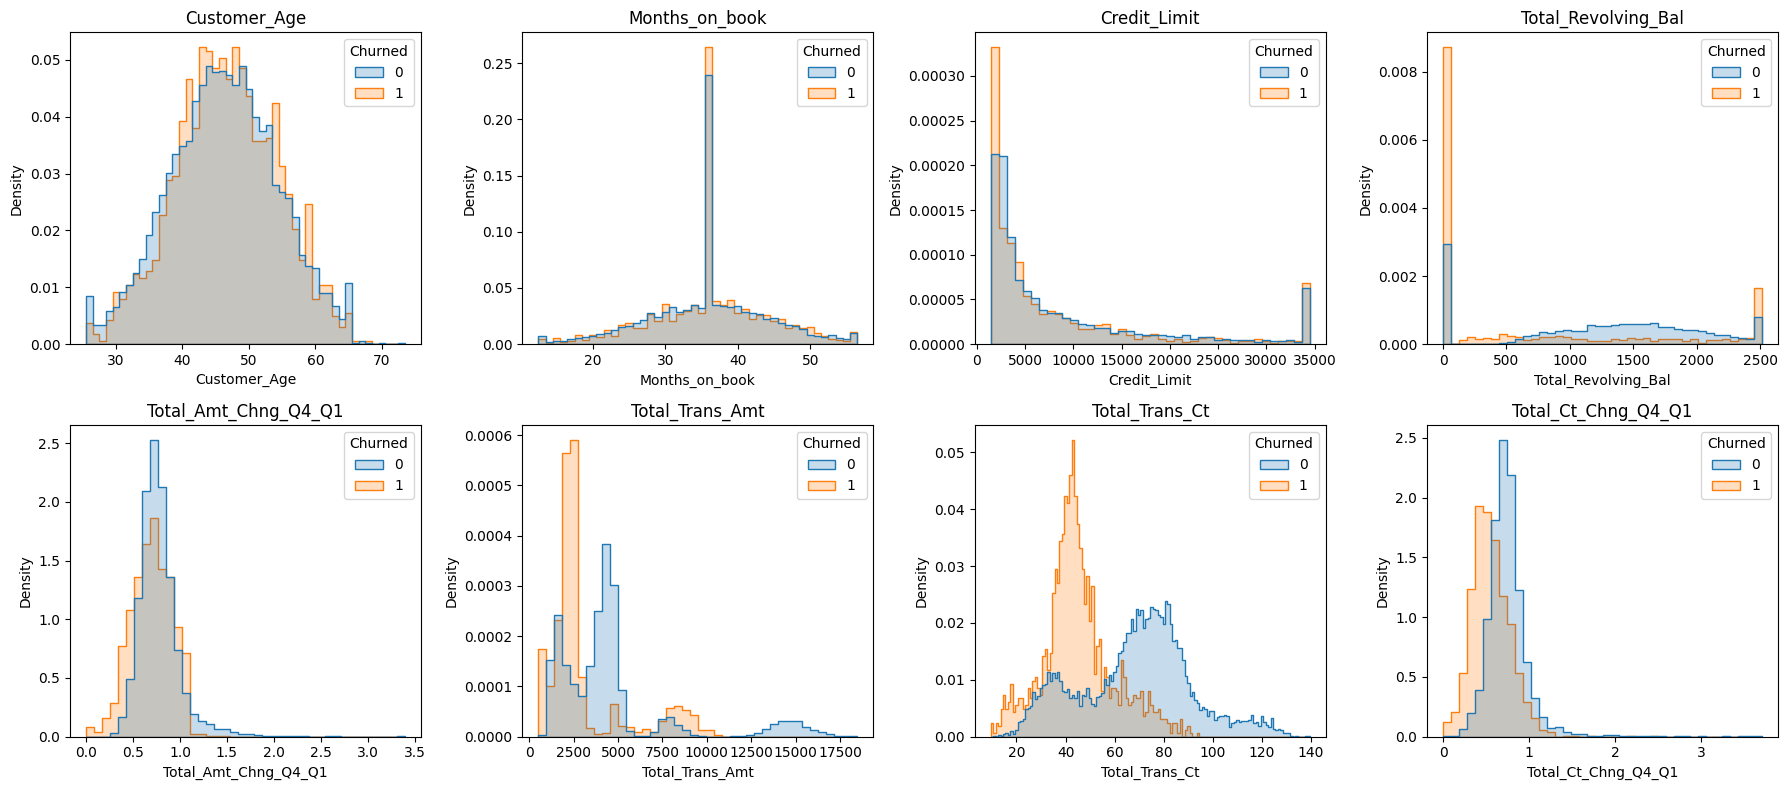

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, cont_cols):
    binning = {"discrete": True} if col in int_cols else {"bins": 40}
    sns.histplot(data=df, x=col, hue="Churned", stat="density", common_norm=False,
                 element="step", ax=ax, **binning)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The clearest differences are in the variables that describe how the card is used:
- `Total_Trans_Ct`: the churned customers made far fewer transactions (median 43 vs 71). Their distribution is concentrated around 40, while the customers who stayed are concentrated around 70 to 80.
- `Total_Trans_Amt`: the churned customers also spent much less (median 2,329 vs 4,100).
- `Total_Revolving_Bal`: the median of the churned customers is 0, so at least half of them carry no balance, while the median of those who stayed is 1,364.
- `Total_Ct_Chng_Q4_Q1`: the churned customers have clearly lower values (median 0.531 vs 0.721), so their number of transactions dropped much more from Q1 to Q4.

`Total_Amt_Chng_Q4_Q1` and `Credit_Limit` differ only a little: churned customers have a slightly lower ratio and are a little more frequent among the lowest limits. `Customer_Age` and `Months_on_book` show practically no difference, with almost identical medians and distributions.

These results also explain some of the shapes seen in the univariate histograms. The large group at zero revolving balance and the lower of the two peaks in `Total_Trans_Ct` are exactly where the churned customers are concentrated, while the group of the highest spenders in `Total_Trans_Amt` contains almost no churned customers. The low Q4/Q1 ratios that the IQR rule flagged as potential outliers are also more common among churned customers, which supports the decision to keep them.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Relationships Between Variables </font></h2>
</div>

So far every variable was compared only with churn. This section looks at how the customer variables relate to each other. This matters for clustering: if two variables carry almost the same information, K-means effectively counts it twice.

The relationships are measured with the Spearman correlation instead of Pearson. Pearson measures only straight-line relationships and reacts strongly to extreme values, while many of our variables are skewed and have piles at their extremes. Spearman compares the ranks of the values, so it captures any relationship in which one variable consistently grows or falls with the other.

Because Spearman works with ranks, it can also include the categorical variables that have a natural order. `Education_Level` is represented by its rank from 0 (Uneducated) to 5 (Doctorate), `Income_Category` from 0 (less than \$40K) to 4 (\$120K +) and `Card_Category` from 0 (Blue) to 3 (Platinum). `Gender` has only two values and is encoded as 0 (F) and 1 (M). Missing values are left out pair by pair. `Marital_Status` has no order and is therefore not included.

### Correlation matrix

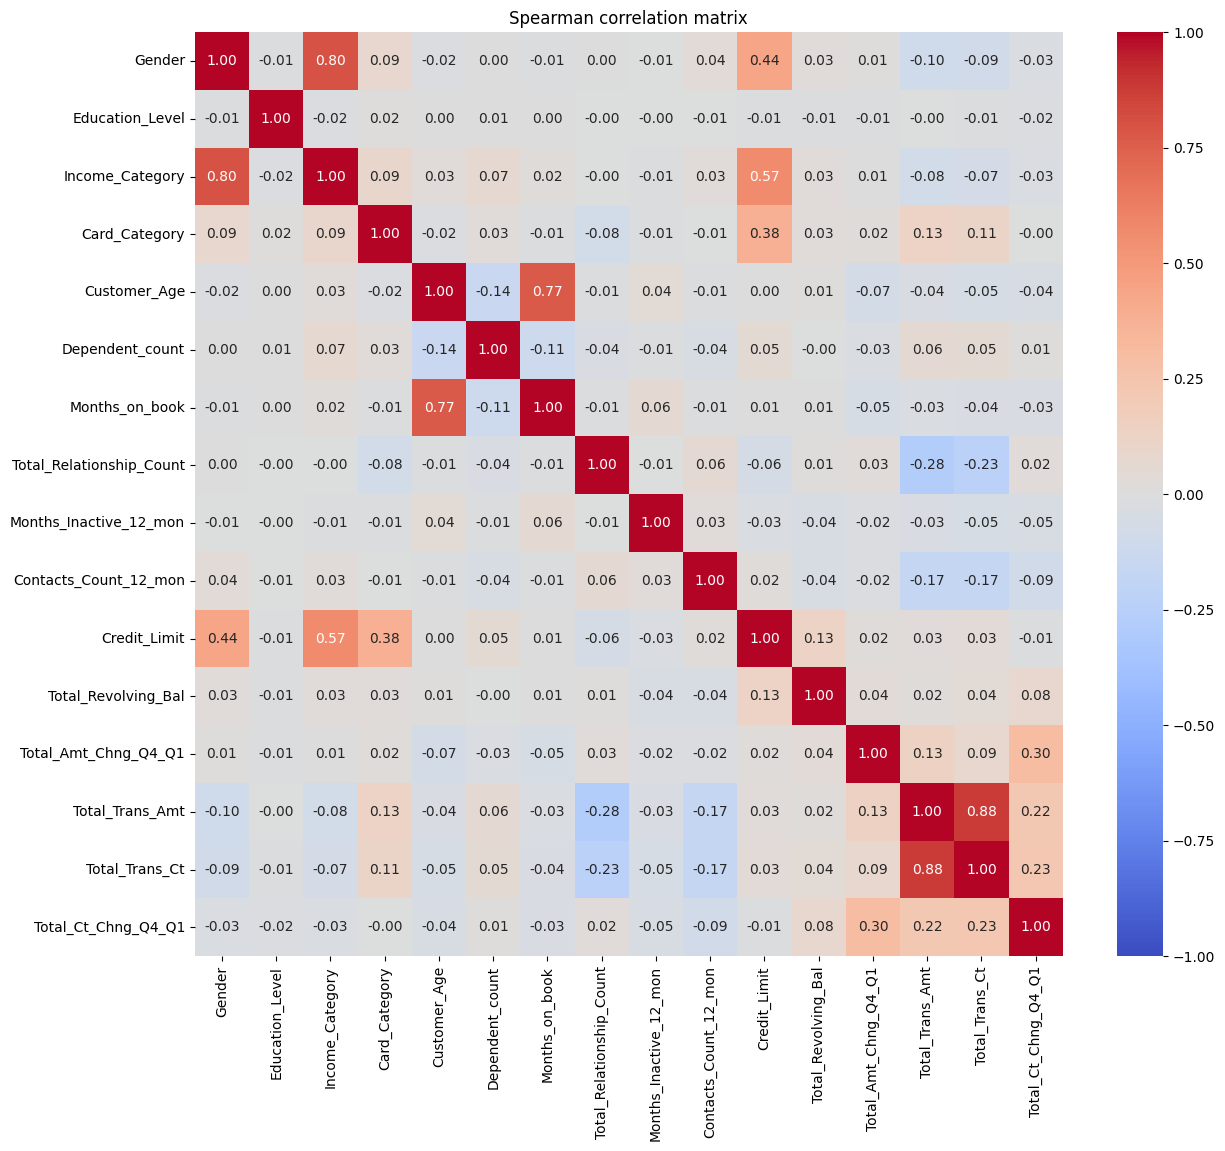

In [32]:
cat_ranks = pd.DataFrame({
    "Gender": (df["Gender"] == "M").astype(int),
    "Education_Level": df["Education_Level"].cat.codes.replace(-1, np.nan),
    "Income_Category": df["Income_Category"].cat.codes.replace(-1, np.nan),
    "Card_Category": df["Card_Category"].cat.codes,
})

spearman_corr = pd.concat([cat_ranks, df[num_cols]], axis=1).corr(method="spearman")

plt.figure(figsize=(14, 12))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation matrix")
plt.show()

The three strongest relationships are `Total_Trans_Amt` with `Total_Trans_Ct` (0.88), `Gender` with `Income_Category` (0.80) and `Customer_Age` with `Months_on_book` (0.77). The credit limit forms a second block: it is related to income (0.57), gender (0.44) and the card tier (0.38). Weaker relationships connect the two Q4/Q1 ratios (0.30) and `Total_Relationship_Count` with the transaction variables (-0.28 and -0.23), so customers with more products tend to use the card a little less.

All other pairs are close to 0. `Education_Level` is unrelated to every other variable, not even to income. `Dependent_count`, `Months_Inactive_12_mon` and `Contacts_Count_12_mon` are almost unrelated to everything else, and even the credit limit and the revolving balance are only weakly related (0.13).

For the clustering, each strong pair carries largely the same information twice. If both variables of a pair are used, K-means gives this information double weight in the distances. This also concerns gender, income and credit limit, which together describe largely the same thing. For each of these groups it is therefore decided later which of the variables enter the clustering, if any, and whether a combination of them, such as the average amount per transaction, can replace them.

### Strongest pairs

A correlation coefficient is a single number, so every pair with at least a moderate relationship (absolute value of at least 0.35) is also shown as a plot. The pairs are taken from the matrix automatically, and the type of plot follows from the types of the two variables:
- two numerical variables: a scatter plot, coloured by `Churned`,
- a categorical and a numerical variable: a boxplot for each category,
- two categorical variables: the number of customers in each combination.

Missing values are shown as a separate category "Missing".

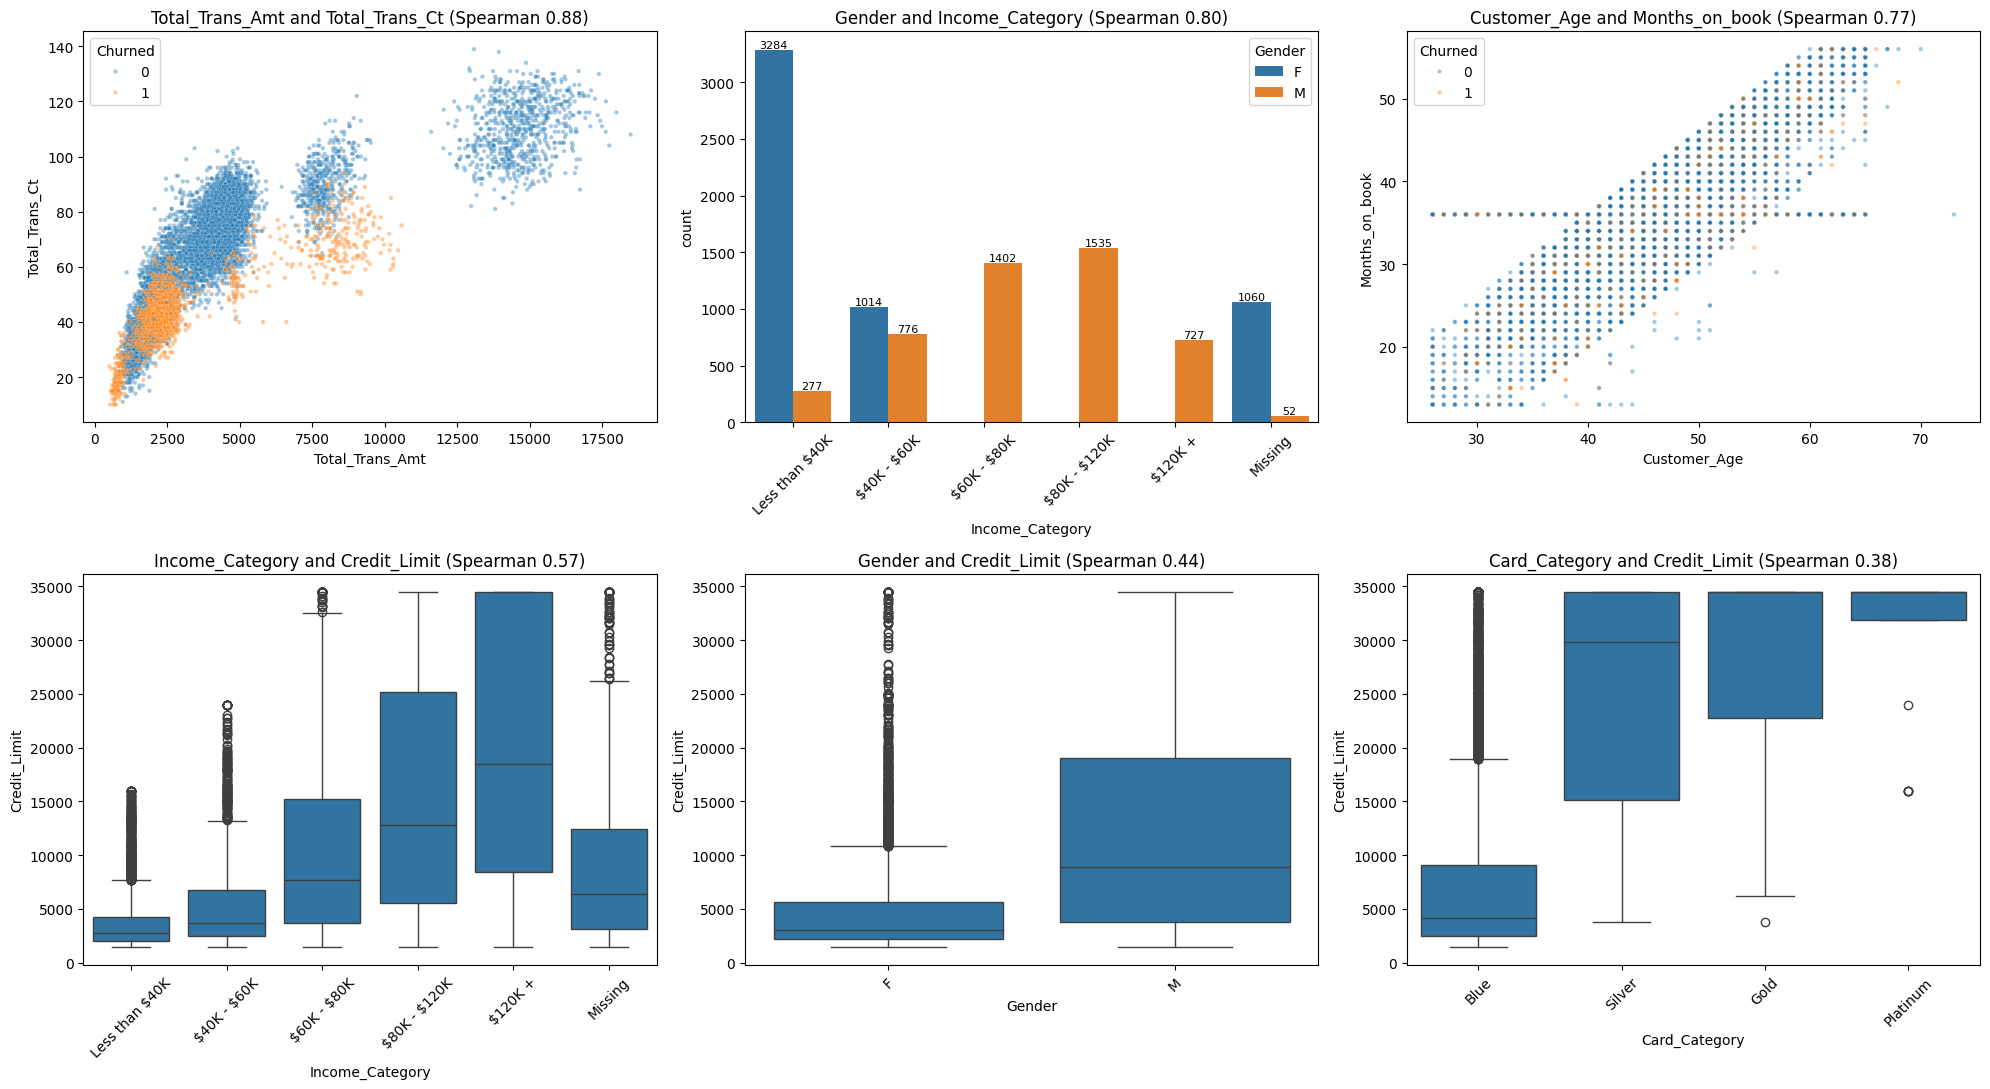

In [33]:
def with_missing(series):
    if isinstance(series.dtype, pd.CategoricalDtype):
        # escape "$", otherwise matplotlib reads "$40K - $60K" as a formula
        series = series.cat.rename_categories(lambda value: str(value).replace("$", r"\$"))
        if series.isna().any():
            series = series.cat.add_categories("Missing").fillna("Missing")
    return series


def plot_relationship(ax, col_a, col_b):
    a_numeric = pd.api.types.is_numeric_dtype(df[col_a])
    b_numeric = pd.api.types.is_numeric_dtype(df[col_b])

    if a_numeric and b_numeric:
        sns.scatterplot(data=df, x=col_a, y=col_b, hue="Churned", alpha=0.4, s=10, ax=ax)
    elif a_numeric or b_numeric:
        cat_col, num_col = (col_b, col_a) if a_numeric else (col_a, col_b)
        sns.boxplot(x=with_missing(df[cat_col]), y=df[num_col], ax=ax)
        ax.tick_params(axis="x", rotation=45)
    else:
        # the variable with more categories goes on the x-axis
        x_col, hue_col = (col_a, col_b) if df[col_a].nunique() >= df[col_b].nunique() else (col_b, col_a)
        sns.countplot(x=with_missing(df[x_col]), hue=df[hue_col], ax=ax)
        for bars in ax.containers:
            ax.bar_label(bars, fontsize=8)
        ax.tick_params(axis="x", rotation=45)

    ax.set_title(f"{col_a} and {col_b} (Spearman {spearman_corr.loc[col_a, col_b]:.2f})")


strong_pairs = [(col_a, col_b) for col_a, col_b in combinations(spearman_corr.columns, 2)
                if abs(spearman_corr.loc[col_a, col_b]) >= 0.35]
strong_pairs.sort(key=lambda pair: abs(spearman_corr.loc[pair]), reverse=True)

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for ax, (col_a, col_b) in zip(axes.flat, strong_pairs):
    plot_relationship(ax, col_a, col_b)
for ax in axes.flat[len(strong_pairs):]:
    ax.remove()

plt.tight_layout()
plt.show()

The plots show several things that the coefficients alone cannot.

`Total_Trans_Amt` and `Total_Trans_Ct` are not related along one straight line. The customers fall into three separate groups: most of them spend up to about 5,500, a second group spends around 7,000 to 10,500, and a third group of the most active customers spends more than about 12,000. Within each group, the number of transactions grows with the amount, but between the groups the amount jumps. In the two lower groups, the churned customers lie at the low end of the transaction count, and the top group contains almost none of them. These groups are the separate peaks already seen in the histogram of `Total_Trans_Amt`, and they are a strong hint of natural groups for the clustering.

`Customer_Age` and `Months_on_book` form a narrow diagonal band, so customers with a longer relationship with the bank are older, as expected. The customers with 36 months on book do not follow this band: they form a horizontal line across almost all ages. This supports the earlier suspicion that 36 was filled in as a default value. The churned customers are spread over the whole band.

The relationship between `Gender` and `Income_Category` is one that real data would hardly show: women appear only in the two lowest income bands, and the three highest bands consist only of men. The customers with missing income are almost all women (1,060 women and 52 men).

The credit limit rises with every income band, and men have clearly higher limits than women. The customers with missing income do not fit simply into this picture. By gender, they would belong to the two lowest bands, but their median credit limit is higher than in both of these bands. At least some of them may therefore have a higher income than their gender alone suggests, which has to be considered when the missing values are handled.

The credit limit also rises with the card tier: most Blue cards have a low limit, while Silver, Gold and Platinum cards mostly have limits close to the maximum. The tiers still overlap, because Blue cards also reach the maximum limit. `Card_Category` therefore mostly repeats information that `Credit_Limit` already contains. Together with its very unbalanced distribution and the missing difference in churn, this is a strong reason to leave `Card_Category` out of the clustering and use it only to describe the clusters afterwards.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Handling Missing Values </font></h2>
</div>

Three columns contain missing values: `Education_Level`, `Marital_Status` and `Income_Category`. The previous sections showed that the gaps fall on the customers independently of each other and that customers with missing values churn like the others. The remaining question is whether the missing values can be inferred from other variables.

In [34]:
missing_now = pd.DataFrame({
    "Missing count": df[miss_cols].isna().sum(),
    "Missing percentage": (df[miss_cols].isna().mean() * 100).round(1)
})

display(missing_now)

,Missing count,Missing percentage
Education_Level,1519,15.0
Marital_Status,749,7.4
Income_Category,1112,11.0


`Education_Level` is unrelated to every other variable in the correlation matrix, and `Marital_Status` has no order, so it could not be included in the correlation matrix, and there is no measured relationship that could be used to infer it. `Income_Category` is different, because it is closely related to gender and credit limit. Before using these relationships to fill in the missing income, we check whether the customers with missing income resemble the customers with known income at all.

In [35]:
income_with_missing = df["Income_Category"].cat.add_categories("Missing").fillna("Missing")

limit_by_income = (
    df.groupby(["Gender", income_with_missing], observed=True)["Credit_Limit"]
    .agg(["count", "median"])
    .rename(columns={"count": "Customers", "median": "Median credit limit"})
)

display(limit_by_income)

Customers  Median credit limit
Gender Income_Category                                
F      Less than $40K        3284               2730.0
       $40K - $60K           1014               3181.0
       Missing               1060               6088.5
M      Less than $40K         277               3453.0
       $40K - $60K            776               4560.5
       $60K - $80K           1402               7660.0
       $80K - $120K          1535              12830.0
       $120K +                727              18442.0
       Missing                 52              10459.5

The 1,060 women with missing income have a median credit limit of 6,088.5. This is about twice the median of women in either known income band (2,730 and 3,181) and close to the median of men earning \$60K - \$80K (7,660). The customers with missing income therefore do not look like typical women with a low income. Since no woman in the data has a known income above \$60K, a likely explanation is that a higher income of women was often recorded as unknown. This cannot be proven from the data, but it means that the missing incomes are probably not random and may hide exactly the higher incomes.

Each column is handled separately, because the correlation matrix and the table above give a different picture for each of them. Before the imputation, the three columns are stored as they are now, so that they can be compared with the result afterwards.

In [36]:
before_imputation = df[miss_cols].copy()

### Education_Level

Filling in the most common value, Graduate, would raise its share from 30.9% to almost half of the customers and create an artificial pile, similar to the spike at 36 months. Keeping "Unknown" as a category would mean giving up the order of the variable, and merging levels would only make it coarser without filling any gaps.

The correlation matrix offers a better option: education is unrelated to every other variable. The missing values are therefore drawn at random from the known values, in the same proportions. Because education does not depend on anything else, a random value cannot break any relationship, and the distribution of the variable stays the same. For a single customer, the drawn value is only a guess and may be wrong. This does not matter here, because education is only analysed as shares of groups of customers, and these shares stay the same. The draw is fixed with `random_state`, so running the notebook again gives exactly the same values.

In [37]:
missing_edu = df["Education_Level"].isna()

df.loc[missing_edu, "Education_Level"] = (
    df["Education_Level"].dropna()
    .sample(missing_edu.sum(), replace=True, random_state=42)
    .to_numpy()
)

### Marital_Status

`Marital_Status` has no order, so the problem of an "Unknown" category in an ordered variable does not apply here. Filling in Married would raise its share from 46.3% to more than half of the customers. A random draw is also not safe, because a nominal variable could not be included in the correlation matrix, so its relationships to the other variables were not measured and could be broken.

The missing values therefore become a category "Unknown" of their own. It does not invent anything and can be shown in the cluster profiles like any other category.

In [38]:
df["Marital_Status"] = df["Marital_Status"].cat.add_categories("Unknown").fillna("Unknown")

### Income_Category

In the correlation matrix, income is related to gender (0.80) and credit limit (0.57). The relationship with gender, however, is probably distorted by the missing values themselves. If higher incomes of women were often recorded as unknown, the known data contains no women with a high income, and part of the 0.80 is a result of this. Filling in the most common band of each gender would build on this distortion: almost all of the missing incomes would become "Less than \$40K", although these customers have about twice the credit limit of the women in that band, and the implausible result that no woman earns more than \$60K would become even stronger. Assigning all of them to the higher bands would go to the other extreme and rely entirely on an explanation that cannot be proven.

The credit limit is not affected by this problem, so the missing income is predicted from the credit limit with the k-nearest neighbours method: for each customer with missing income, the k customers with known income and the closest credit limit are found, and their most common income band is used. This follows what the data shows about these customers, namely their high limits, without assuming more than that. Because credit limit and income are only moderately related, the individual values remain uncertain.

After the imputation, the relationships of income with gender and credit limit are measured again, because the relationship with gender may become weaker. This shows how much of the overlap between gender and income was caused by the missing values themselves.

The number of neighbours k has to be chosen first. A small k follows only a few customers and is easily misled by single values, while a large k averages over many customers. k is therefore chosen in the same way as in a classification task: the income of a part of the customers with known income is hidden, predicted from the remaining customers, and the share of correct predictions (accuracy) is compared for several values of k. Each value is tested on five different random splits and the results are averaged, so that no single split decides. The chosen k is the smallest one whose accuracy is within one percentage point of the best result, because a larger k would hardly improve the predictions. The dashed line shows the accuracy of always predicting the most common band.

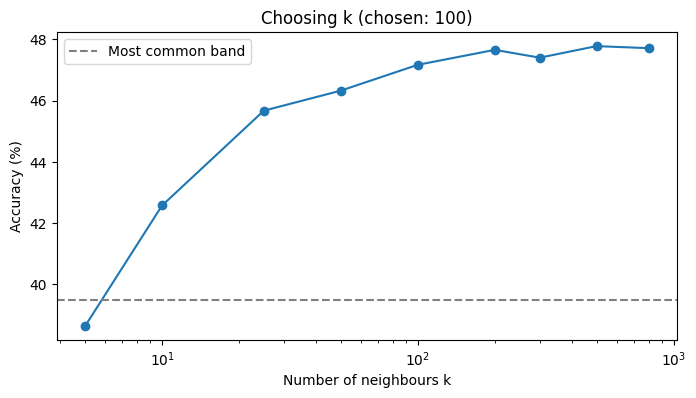

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

known_income = df["Income_Category"].notna()
X_known = df.loc[known_income, ["Credit_Limit"]]
y_known = df.loc[known_income, "Income_Category"].astype(str)

k_values = [5, 10, 25, 50, 100, 200, 300, 500, 800]
accuracy_by_k = {}

for k in k_values:
    scores = []
    for seed in range(5):
        X_train, X_test, y_train, y_test = train_test_split(X_known, y_known, test_size=0.2, random_state=seed)
        model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
        scores.append(accuracy_score(y_test, model.predict(X_test)))
    accuracy_by_k[k] = np.mean(scores) * 100

best_accuracy = max(accuracy_by_k.values())
chosen_k = min(k for k, accuracy in accuracy_by_k.items() if accuracy >= best_accuracy - 1)
baseline = y_known.value_counts(normalize=True).max() * 100

plt.figure(figsize=(8, 4))
plt.plot(list(accuracy_by_k), list(accuracy_by_k.values()), marker="o")
plt.axhline(baseline, color="gray", linestyle="--", label="Most common band")
plt.xscale("log")
plt.xlabel("Number of neighbours k")
plt.ylabel("Accuracy (%)")
plt.title(f"Choosing k (chosen: {chosen_k})")
plt.legend()
plt.show()

The accuracy rises quickly with k. With only 5 neighbours, the predictions are even worse than always choosing the most common band (the dashed line, just under 40%), but from 10 neighbours on they are clearly better. From about 100 neighbours on, the accuracy hardly changes and stays around 47 to 48%, so k = 100 was chosen. An accuracy below 50% also shows how uncertain the individual values are: the credit limit narrows the income down, but it does not determine it.

In [40]:
income_model = KNeighborsClassifier(n_neighbors=chosen_k).fit(X_known, y_known)

df.loc[~known_income, "Income_Category"] = income_model.predict(df.loc[~known_income, ["Credit_Limit"]])

### Check

After the imputation, no missing values should remain. Each column is then checked in the way that matters for it: for education, whether the shares stayed the same, for marital status, how large the new category "Unknown" is, and for income, how the bands of women and men changed. For each gender, the table shows the number of customers in each band before and after the imputation, the share of each band within that gender (%), and at the end how many missing incomes were filled in with each band.

In [41]:
display(df[miss_cols].isna().sum().to_frame("Missing after imputation"))

edu_shares = pd.DataFrame({
    "Before (%)": before_imputation["Education_Level"].value_counts(normalize=True, sort=False) * 100,
    "After (%)": df["Education_Level"].value_counts(normalize=True, sort=False) * 100,
}).round(1)
edu_shares.index.name = None
display(edu_shares)

marital_after = pd.DataFrame({
    "Customers": df["Marital_Status"].value_counts(sort=False),
    "Share (%)": (df["Marital_Status"].value_counts(normalize=True, sort=False) * 100).round(1),
})
marital_after.index.name = None
display(marital_after)

before_counts = pd.crosstab(before_imputation["Income_Category"], df["Gender"])
after_counts = pd.crosstab(df["Income_Category"], df["Gender"])
imputed_counts = pd.crosstab(df.loc[~known_income, "Income_Category"], df.loc[~known_income, "Gender"])

income_check = pd.DataFrame(index=after_counts.index)
for gender in ["F", "M"]:
    income_check[f"{gender} before"] = before_counts[gender]
    income_check[f"{gender} after"] = after_counts[gender]
    income_check[f"{gender} before (%)"] = before_counts[gender] / before_counts[gender].sum() * 100
    income_check[f"{gender} after (%)"] = after_counts[gender] / after_counts[gender].sum() * 100
for gender in ["F", "M"]:
    income_check[f"Imputed {gender}"] = imputed_counts[gender]

income_check = income_check.fillna(0).round(1)
count_cols = [col for col in income_check.columns if "(%)" not in col]
income_check[count_cols] = income_check[count_cols].astype(int)
income_check.index.name = None
display(income_check)

,Missing after imputation
Education_Level,0
Marital_Status,0
Income_Category,0


,Before (%),After (%)
Uneducated,17.3,17.4
High School,23.4,23.4
College,11.8,11.8
Graduate,36.3,36.0
Post-Graduate,6.0,6.1
Doctorate,5.2,5.4


,Customers,Share (%)
Divorced,748,7.4
Married,4687,46.3
Single,3943,38.9
Unknown,749,7.4


,F before,F after,F before (%),F after (%),M before,M after,M before (%),M after (%),Imputed F,Imputed M
Less than $40K,3284,3941,76.4,73.6,277,299,5.9,6.3,657,22
$40K - $60K,1014,1072,23.6,20.0,776,781,16.5,16.4,58,5
$60K - $80K,0,77,0.0,1.4,1402,1405,29.7,29.5,77,3
$80K - $120K,0,268,0.0,5.0,1535,1557,32.5,32.6,268,22
$120K +,0,0,0.0,0.0,727,727,15.4,15.2,0,0


Finally, the relationships of income with gender and credit limit are measured again with the same Spearman correlation as in the matrix.

In [42]:
gender_codes = (df["Gender"] == "M").astype(int)
income_ranks = {
    "Before": before_imputation["Income_Category"].cat.codes.replace(-1, np.nan),
    "After": df["Income_Category"].cat.codes,
}

income_corr = pd.DataFrame({
    when: {
        "Gender": ranks.corr(gender_codes, method="spearman"),
        "Credit_Limit": ranks.corr(df["Credit_Limit"], method="spearman"),
    }
    for when, ranks in income_ranks.items()
}).round(2)

display(income_corr)

,Before,After
Gender,0.80,0.74
Credit_Limit,0.57,0.58


No missing values remain. The random draw left the education shares practically unchanged, and "Unknown" became a marital status group as large as Divorced.

For income, the imputation mainly affected the women. Of the 1,060 women whose income was missing, 345 were placed in a band above \$60K, most of them (268) in "\$80K - \$120K", which matches their high credit limits. As a result, 6.4% of all women in the dataset now have an income above \$60K, while before there were none. The men barely changed, because only very few of them had a missing income.

The relationship between income and gender became weaker (from 0.80 to 0.74), but it remains strong, because all women whose income was known still earn at most \$60K. The relationship with the credit limit did not change. Gender and income therefore still describe largely the same split of the customers, so using both of them in the clustering would count this split twice. Which variables enter the clustering is decided in the next section, together with the other strongly related pairs from the correlation analysis.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Feature Selection and Engineering </font></h2>
</div>

The clustering is built only on variables that describe the behaviour of the customers, that is, how they use the card and the bank. The demographic variables are not used to form the clusters. Instead, they are added to the cluster profiles afterwards, to describe who the customers in each cluster are.

There are several reasons for this. The analysis so far has shown that churn is related to behaviour, such as the number of transactions, inactivity and contacts, while the demographic variables differ only little in churn. If gender, income or age influence behaviour, this influence already appears in the behaviour variables. Leaving them out of the clustering also makes it possible to check this: if a cluster formed only from behaviour turns out to consist mostly of one group of customers, this is a finding, not a consequence of how the clusters were built. Finally, K-means measures distances, which are meaningful for numbers but not for categories, and segments based on gender could hardly be used for decisions of the bank.

### New features

- `Avg_Trans_Value` is the average amount per transaction. `Total_Trans_Amt` and `Total_Trans_Ct` were the most strongly related pair in the dataset. The amount is exactly the number of transactions times the average amount per transaction, so the pair "number of transactions and average amount" contains the same information as the pair "amount and number of transactions", but separates how often a customer uses the card from how much they spend per purchase. `Total_Trans_Amt` is therefore replaced by `Avg_Trans_Value` in the clustering.
- `Utilization_Ratio` is the share of the credit limit the customer uses. It is the same quantity as the original `Avg_Utilization_Ratio`, which was removed in the redundancy check, because at that point both the balance and the limit were kept and the ratio added nothing to them. In the clustering, however, the credit limit is not used: it is set by the bank and closely related to income, so it describes the customer rather than their behaviour. The utilization ratio keeps the behavioural part of the balance and the limit, while the size of the account is left to the cluster profiles.
- `Open_To_Buy` is the credit still available, recomputed as limit minus balance for the cluster profiles. The "Avg" of the original name is left out, because it was never an average.
- `Zero_Balance` marks the customers who carry no revolving balance. They form a large separate group in the distribution of the balance, and churned customers are concentrated in it. As a yes/no variable it is not suitable for K-means, so it is used only in the cluster profiles.

In [43]:
df["Avg_Trans_Value"] = df["Total_Trans_Amt"] / df["Total_Trans_Ct"]
df["Utilization_Ratio"] = df["Total_Revolving_Bal"] / df["Credit_Limit"]
df["Open_To_Buy"] = df["Credit_Limit"] - df["Total_Revolving_Bal"]
df["Zero_Balance"] = (df["Total_Revolving_Bal"] == 0).astype(int)

df[["Avg_Trans_Value", "Utilization_Ratio", "Open_To_Buy", "Zero_Balance"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_Trans_Value,10127.0,62.612717,26.404198,19.137931,47.514573,55.794872,65.476673,190.193182
Utilization_Ratio,10127.0,0.274892,0.275689,0.000000,0.022714,0.175650,0.502691,0.998768
Open_To_Buy,10127.0,7469.139637,9090.685324,3.000000,1324.500000,3474.000000,9859.000000,34516.000000
Zero_Balance,10127.0,0.243902,0.429456,0.000000,0.000000,0.000000,0.000000,1.000000


### Clustering features and profile features

The clustering uses nine behaviour variables: the original variables that describe how long and how actively a customer uses the bank, and the two engineered ratios. All other variables, including the target `Churned`, are kept for the cluster profiles.

In [44]:
cluster_features = [
    "Months_on_book",
    "Total_Relationship_Count",
    "Months_Inactive_12_mon",
    "Contacts_Count_12_mon",
    "Total_Trans_Ct",
    "Total_Amt_Chng_Q4_Q1",
    "Total_Ct_Chng_Q4_Q1",
    "Avg_Trans_Value",
    "Utilization_Ratio",
]

profile_features = [
    "Customer_Age", "Gender", "Dependent_count", "Education_Level", "Marital_Status", "Income_Category",
    "Card_Category", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt", "Open_To_Buy", "Zero_Balance",
    "Churned",
]

print("Clustering features:", len(cluster_features))
print("Profile features:", len(profile_features))

Clustering features: 9
Profile features: 13


### Check

The correlation matrix of the clustering features shows whether the selection removed the strongest overlaps found earlier.

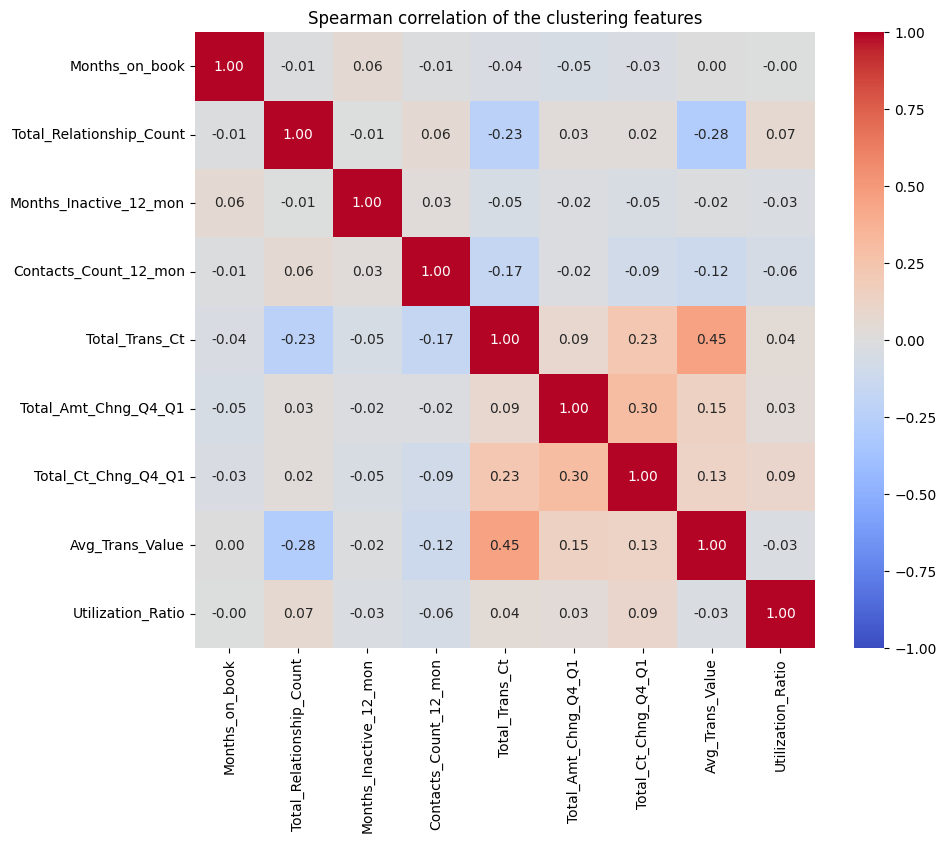

In [45]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[cluster_features].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation of the clustering features")
plt.show()

None of the clustering features is strongly related to another. The strongest remaining pair is `Total_Trans_Ct` with `Avg_Trans_Value` (0.45), which replaces the pair of amount and number of transactions with a correlation of 0.88. The other strong pairs from the full matrix are gone, because age, gender, income and the credit limit are no longer clustering features. What remains are weak to moderate relationships, such as the two Q4/Q1 ratios (0.30) and `Total_Relationship_Count` with the two transaction features, so customers with more products tend to make fewer and smaller purchases. Most pairs are close to 0, so each feature adds its own information to the distances.

### Distributions of the clustering features

Before the clustering, the scales and shapes of the nine features are shown together, because K-means compares customers by distances, and both affect these distances. Whole-number features again get one bar per value.

,min,median,max,skew
Months_on_book,13.00,36.00,56.00,-0.11
Total_Relationship_Count,1.00,4.00,6.00,-0.16
Months_Inactive_12_mon,0.00,2.00,6.00,0.63
Contacts_Count_12_mon,0.00,2.00,6.00,0.01
Total_Trans_Ct,10.00,67.00,139.00,0.15
Total_Amt_Chng_Q4_Q1,0.00,0.74,3.40,1.73
Total_Ct_Chng_Q4_Q1,0.00,0.70,3.71,2.06
Avg_Trans_Value,19.14,55.79,190.19,1.88
Utilization_Ratio,0.00,0.18,1.00,0.72


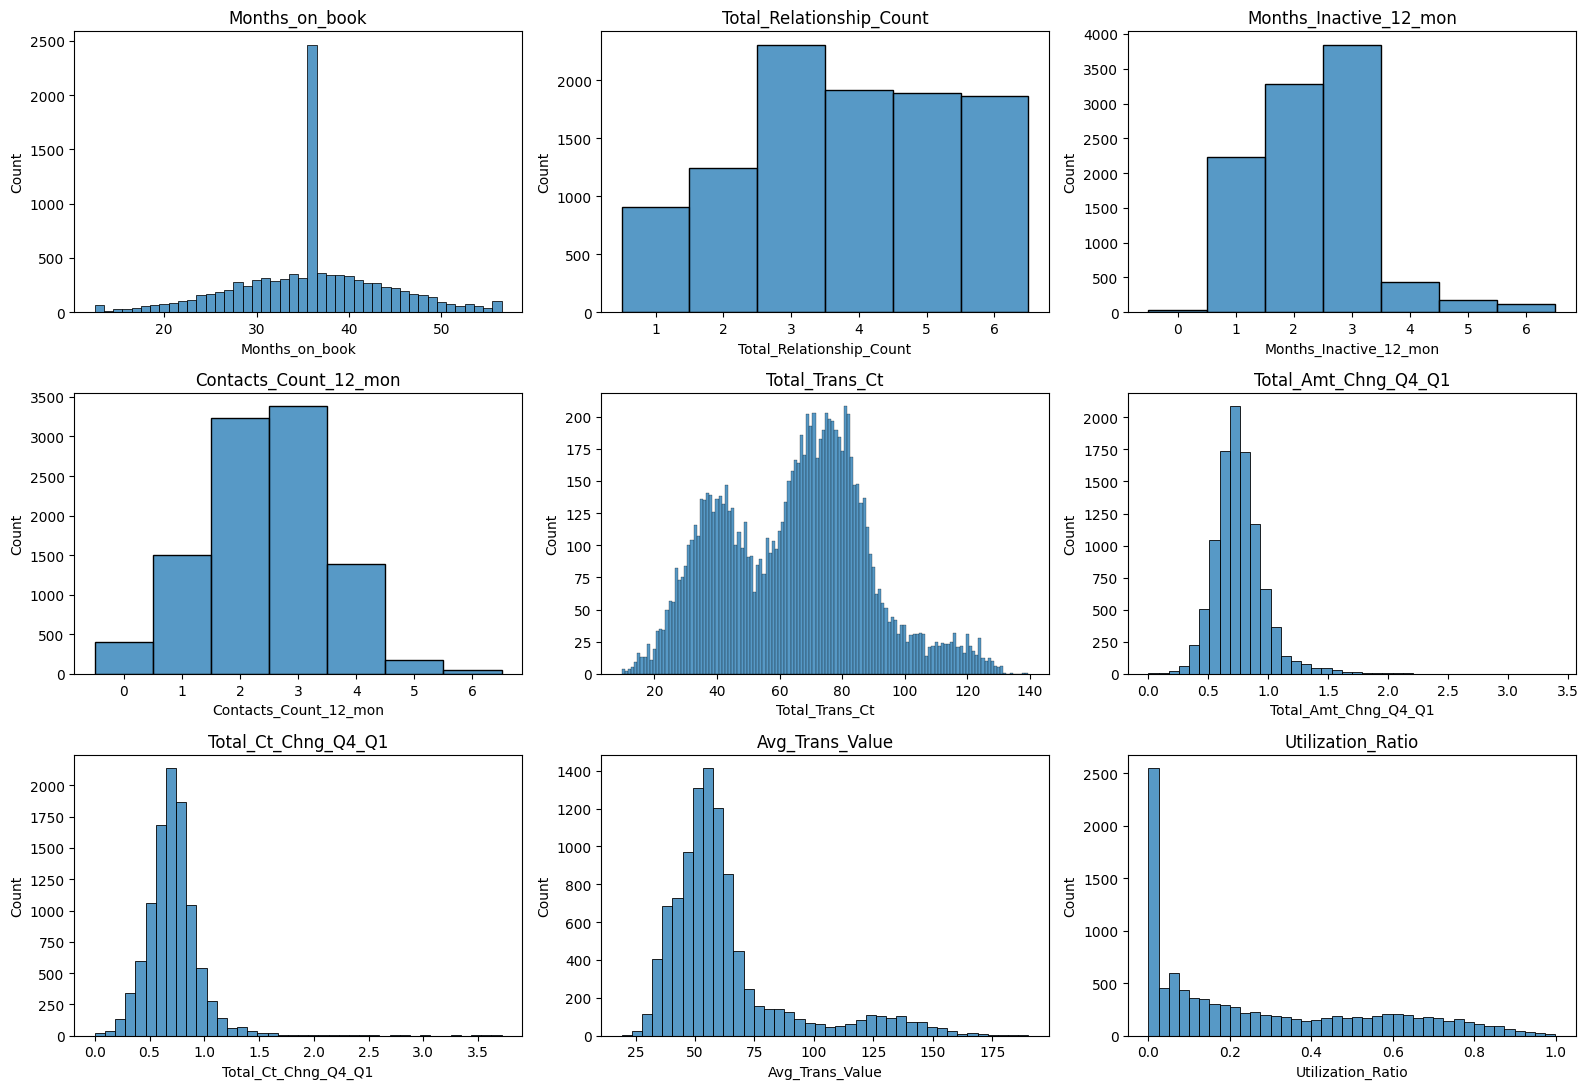

In [46]:
display(df[cluster_features].agg(["min", "median", "max", "skew"]).T.round(2))

fig, axes = plt.subplots(3, 3, figsize=(16, 11))

for ax, col in zip(axes.flat, cluster_features):
    binning = {"discrete": True} if pd.api.types.is_integer_dtype(df[col]) else {"bins": 40}
    sns.histplot(data=df, x=col, ax=ax, **binning)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The features lie on very different scales, from `Utilization_Ratio` between 0 and 1 to `Total_Trans_Ct` and `Avg_Trans_Value` with values above 100, so in their original units the features with the largest ranges would dominate the distances. Three features are strongly right-skewed: the two Q4/Q1 ratios and `Avg_Trans_Value`. `Utilization_Ratio` is only moderately skewed, but instead of a bell shape it has a large pile at 0. Both the scales and the skewness have to be handled before the clustering.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Preparing the Data for K-means </font></h2>
</div>

The clustering features are prepared in a separate table `X`, while `df` keeps the original values for describing the clusters later.

### Transforming the skewed features

K-means compares customers by distances. The scaling below changes the units of a feature but not the shape of its distribution, so a customer far out in a tail stays far out after scaling and can dominate the distances or pull a cluster centre towards itself. Whether a feature needs a transformation is therefore judged by three things: the shape of its histogram, its skewness, and how far its most extreme customers lie from the mean, measured in standard deviations.

In [47]:
def tail_summary(data):
    z = (data - data.mean()) / data.std()
    return pd.DataFrame({
        "Skewness": data.skew(),
        "Max distance (std)": z.abs().max(),
        "Customers beyond 4 std": (z.abs() > 4).sum(),
    }).round(2)


display(tail_summary(df[cluster_features]))

,Skewness,Max distance (std),Customers beyond 4 std
Months_on_book,-0.11,2.87,0
Total_Relationship_Count,-0.16,1.81,0
Months_Inactive_12_mon,0.63,3.62,0
Contacts_Count_12_mon,0.01,3.20,0
Total_Trans_Ct,0.15,3.16,0
Total_Amt_Chng_Q4_Q1,1.73,12.03,58
Total_Ct_Chng_Q4_Q1,2.06,12.61,57
Avg_Trans_Value,1.88,4.83,21
Utilization_Ratio,0.72,2.63,0


The two Q4/Q1 ratios and `Avg_Trans_Value` are the only features with customers more than 4 standard deviations from the mean: almost 60 in each ratio, reaching up to about 12 standard deviations, and 21 in `Avg_Trans_Value`. All three are also strongly right-skewed, so they are transformed with `np.log1p`, which computes log(1 + x). The +1 is needed because the ratios contain values of exactly 0.

`Total_Trans_Ct` has a short tail above 130 transactions, but even its most active customer lies only about 3 standard deviations from the mean, so it is left as it is, like the remaining features.

Before                                            \
                     Skewness Max distance (std) Customers beyond 4 std   
Total_Amt_Chng_Q4_Q1     1.73              12.03                     58   
Total_Ct_Chng_Q4_Q1      2.06              12.61                     57   
Avg_Trans_Value          1.88               4.83                     21   

                     After log1p                                            
                        Skewness Max distance (std) Customers beyond 4 std  
Total_Amt_Chng_Q4_Q1        0.65               7.84                     42  
Total_Ct_Chng_Q4_Q1         0.51               7.81                     48  
Avg_Trans_Value             0.93               3.38                      0

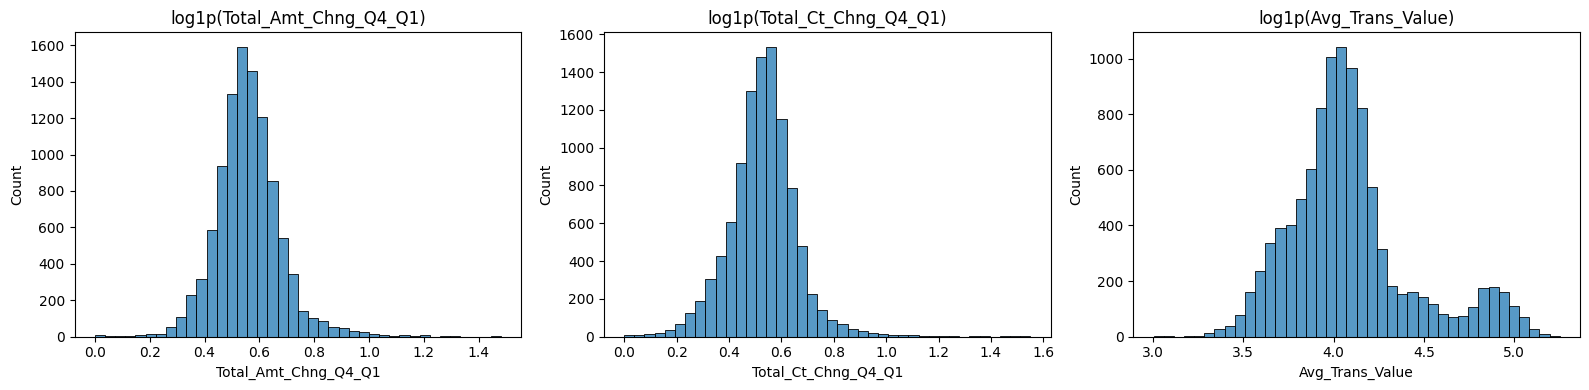

In [48]:
log_features = ["Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1", "Avg_Trans_Value"]

X_raw = df[cluster_features].copy()
X_raw[log_features] = np.log1p(X_raw[log_features])

display(pd.concat({
    "Before": tail_summary(df[log_features]),
    "After log1p": tail_summary(X_raw[log_features]),
}, axis=1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, log_features):
    sns.histplot(data=X_raw, x=col, bins=40, ax=ax)
    ax.set_title(f"log1p({col})")

plt.tight_layout()
plt.show()

The transformation reduced the skewness of all three features to below 1. For `Avg_Trans_Value` it also removed the extreme values: no customer lies more than 4 standard deviations from the mean anymore, and the high spenders remain visible as a separate peak. The two ratios now have a narrow, almost symmetric peak, but thin tails on both sides remain. They still reach about 8 standard deviations, with 42 and 48 customers beyond 4, so these customers stay far from the rest and have to be kept in mind when the clusters are interpreted.

### Scaling

After the transformation, the features still have very different ranges. `StandardScaler` shifts every feature to a mean of 0 and scales it to a standard deviation of 1, so that each feature has the same influence on the distances. A difference of 1 then means "one standard deviation" for every feature, whether it is a number of transactions or a ratio.

In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=cluster_features, index=df.index)

display(X.agg(["mean", "std", "min", "max"]).T.round(2))

,mean,std,min,max
Months_on_book,-0.0,1.0,-2.87,2.51
Total_Relationship_Count,-0.0,1.0,-1.81,1.41
Months_Inactive_12_mon,0.0,1.0,-2.32,3.62
Contacts_Count_12_mon,-0.0,1.0,-2.22,3.20
Total_Trans_Ct,-0.0,1.0,-2.34,3.16
Total_Amt_Chng_Q4_Q1,0.0,1.0,-4.74,7.84
Total_Ct_Chng_Q4_Q1,0.0,1.0,-4.04,7.81
Avg_Trans_Value,-0.0,1.0,-3.14,3.38
Utilization_Ratio,0.0,1.0,-1.00,2.63


All nine features now have a mean of 0 and a standard deviation of 1, so their minimum and maximum show directly how many standard deviations the most extreme customers lie from the mean. Apart from the two Q4/Q1 ratios, all values lie between -3.14 and 3.62. The two ratios reach from about -4.7 to 7.8 because of their remaining tails.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> K-means: Choosing the Number of Clusters </font></h2>
</div>

K-means needs the number of clusters k in advance. It is chosen by comparing the results for k from 2 to 10 with three measures:
- **Inertia** is the sum of squared distances of all customers to the centre of their cluster. It always decreases with more clusters, so the aim is the "elbow", the point after which additional clusters improve it only a little.
- **Silhouette score** compares, for each customer, the distance to its own cluster with the distance to the nearest other cluster, and averages this over all customers. It ranges from -1 to 1, and higher values mean more compact and better separated clusters.
- **Size of the smallest cluster** shows whether a solution contains a tiny cluster, for example one formed only by the customers in the remaining tails of the Q4/Q1 ratios.

Each model is fitted with 10 different random starts (`n_init=10`), and `random_state` makes the result reproducible.

,Inertia,Silhouette,Smallest cluster
k,,,
2,78948.469,0.149,2392
3,70411.785,0.132,2004
4,65037.396,0.134,1655
5,61315.973,0.124,1131
6,58523.718,0.120,824
7,56149.270,0.121,739
8,54053.512,0.122,526
9,52397.029,0.117,497
10,51042.776,0.116,482


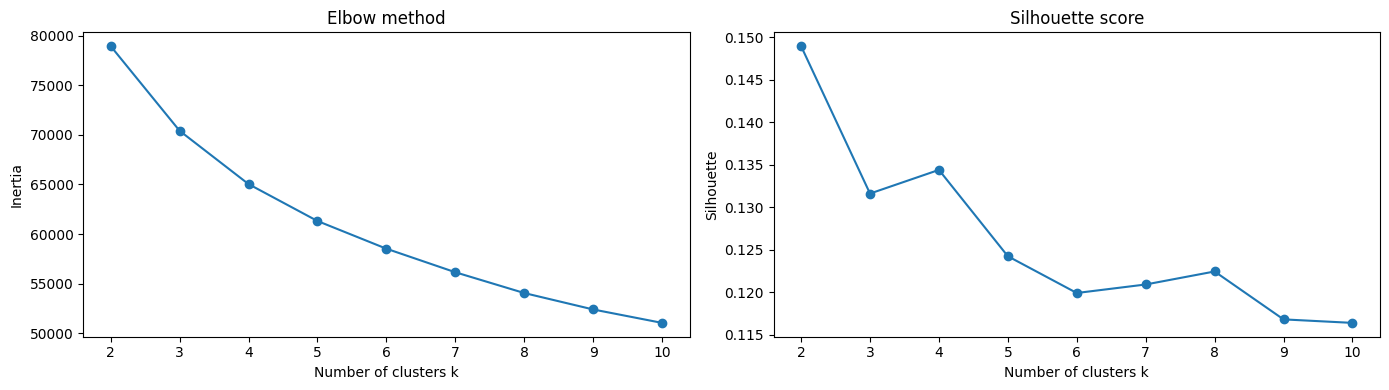

In [50]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    k_scores.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X, labels),
        "Smallest cluster": pd.Series(labels).value_counts().min(),
    })

k_scores = pd.DataFrame(k_scores).set_index("k")
display(k_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(k_scores.index, k_scores["Inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_scores.index, k_scores["Silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

The inertia curve has no sharp elbow. The largest drops come from 2 to 3 and from 3 to 4 clusters, after which every additional cluster brings a smaller gain, so the bend lies at around 3 to 4 clusters. The silhouette score is highest for k = 2 (0.149). Apart from that, it has a local peak at k = 4 (0.134), slightly above k = 3 (0.132), and from k = 5 on it stays lower. None of the solutions contains a very small cluster. Even with 10 clusters the smallest one has 482 customers, so the customers in the remaining tails of the Q4/Q1 ratios do not form a cluster of their own.

- k = 2 has the highest silhouette score, but two groups are too coarse to describe different types of customers, and the inertia still drops strongly after it.
- With 5 or more clusters, the silhouette score drops and stays lower, the smallest cluster shrinks, and every additional cluster improves the inertia less and less.

This leaves k = 3 and k = 4. Both lie at the bend of the inertia curve, and the difference between their silhouette scores is negligible. k = 4 gives the more balanced solution: its smallest cluster has 1,655 customers, about two thirds of an average cluster. The measures alone cannot decide between the two, so both are compared in the stability check below.

All silhouette scores are low, between 0.12 and 0.15. The clusters are therefore not clearly separated from each other, and many customers lie near the border between two clusters. The customers form overlapping groups rather than sharply distinct ones, so the clusters are interpreted as typical customer profiles, not as strictly separate segments.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Stability of the Clustering </font></h2>
</div>

K-means starts from randomly placed centres, so different starts can end in different clusterings. A clustering that changes strongly from one start to another should not be interpreted. For both k = 3 and k = 4, K-means is therefore run ten times with a single random start each (`n_init=1`) and a different `random_state`, and every run is compared with the first one.

The comparison uses the Adjusted Rand Index (ARI). It measures how similarly two clusterings group the customers, regardless of how the clusters are numbered. A value of 1 means that both runs put exactly the same customers together, and a value around 0 means that the agreement is no better than chance.

,k = 3,k = 4
mean,0.983,0.968
min,0.919,0.940


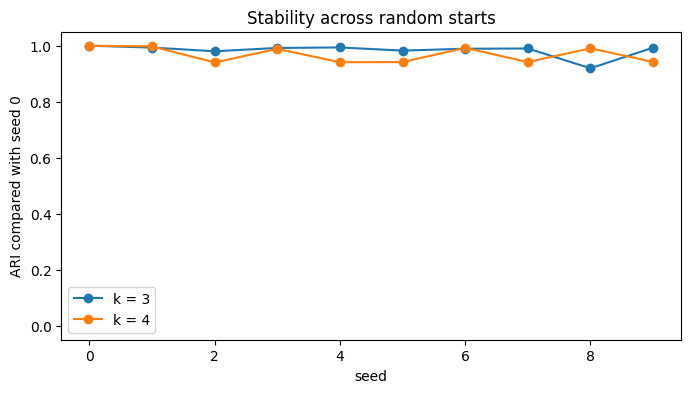

In [51]:
from sklearn.metrics import adjusted_rand_score


def stability_ari(k, n_runs=10):
    runs = [KMeans(n_clusters=k, n_init=1, random_state=seed).fit_predict(X) for seed in range(n_runs)]
    return [adjusted_rand_score(runs[0], labels) for labels in runs]


stability = pd.DataFrame({f"k = {k}": stability_ari(k) for k in [3, 4]})
stability.index.name = "seed"

display(stability.agg(["mean", "min"]).round(3))

stability.plot(marker="o", figsize=(8, 4))
plt.ylim(-0.05, 1.05)
plt.ylabel("ARI compared with seed 0")
plt.title("Stability across random starts")
plt.show()

Both solutions are very stable. In every run, the agreement with the first run stays above 0.9, so different random starts lead to practically the same clusters. k = 3 has a slightly higher average agreement (0.983 vs 0.968), while k = 4 has a higher minimum (0.940 vs 0.919). These differences are small, so stability does not decide between the two solutions either.

The decision therefore depends on what the clusters mean. If the fourth cluster describes a different type of customer, k = 4 adds information. If it only splits one of the three clusters into two similar groups, k = 3 is the better choice. This is checked by comparing the profiles of both solutions.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Comparing the Solutions with 3 and 4 Clusters </font></h2>
</div>

Both solutions are fitted on the prepared features, and each customer gets the number of their cluster in `df`. The numbers have no meaning, they only name the groups. All plots and tables below are produced by the same set of functions, and `COMPARE_K` decides which solutions are compared, so other numbers of clusters can be inspected by changing only this list. The same cluster number always has the same colour.

In [52]:
COMPARE_K = [3, 4]


def fit_clusters(k):
    df[f"Cluster_k{k}"] = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)


def cluster_data(k):
    data = df.copy()
    data["Cluster"] = df[f"Cluster_k{k}"].astype(str)
    return data, sorted(data["Cluster"].unique())


for k in COMPARE_K:
    fit_clusters(k)

### Exploring each solution

For each solution, the pair plot shows every pair of the nine clustering features once, in their original units. The diagonal shows the distribution of each feature within each cluster, scaled separately for every cluster so that small clusters remain visible. Each scatter plot shows only two of the nine features, so a cluster that overlaps with others in one plot can be well separated in another.

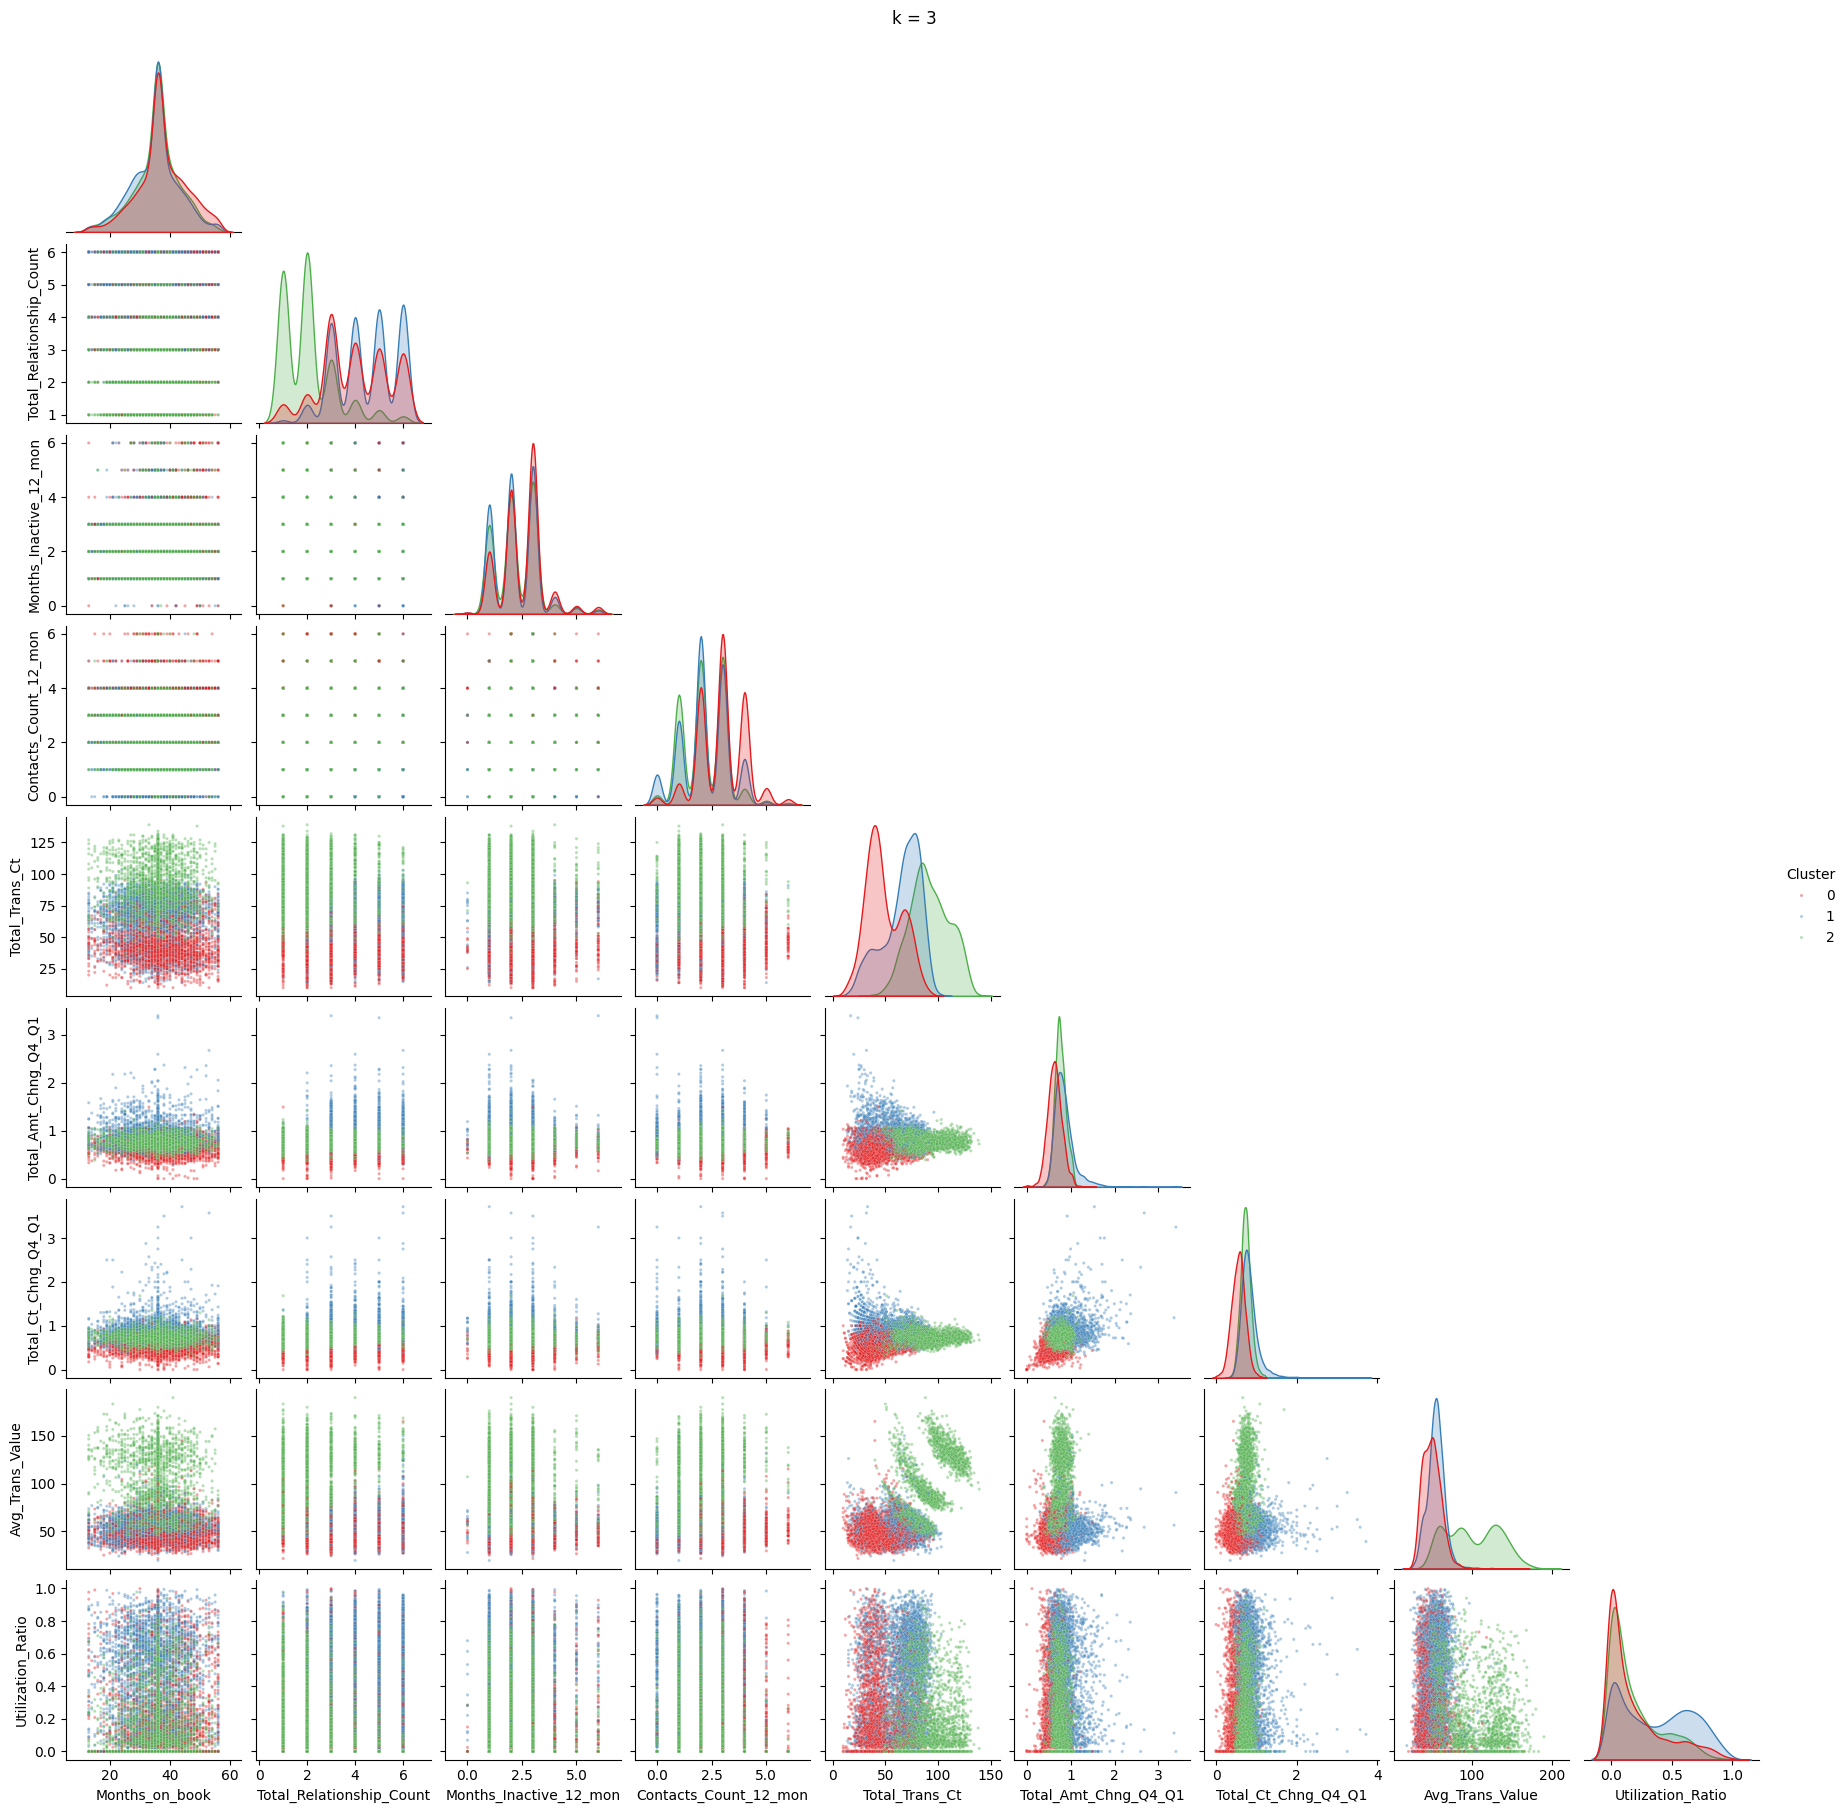

In [53]:
def plot_cluster_pairs(k, features=cluster_features):
    data, order = cluster_data(k)
    grid = sns.pairplot(
        data[features + ["Cluster"]], hue="Cluster", hue_order=order, palette="Set1", corner=True, height=2,
        plot_kws={"s": 5, "alpha": 0.4}, diag_kws={"common_norm": False},
    )
    grid.figure.suptitle(f"k = {k}", y=1.01)
    plt.show()


plot_cluster_pairs(COMPARE_K[0])

The clearest separation comes from the transaction features. In `Total_Trans_Ct` the three clusters lie at different levels: cluster 0 at low counts around 40, cluster 1 in the middle and cluster 2 at the highest counts. `Avg_Trans_Value` and `Total_Relationship_Count` set cluster 2 apart from the other two: its customers spend much more per purchase, in two separate groups, and mostly hold only one or two products, while clusters 0 and 1 lie on top of each other in both features. The two Q4/Q1 ratios and `Contacts_Count_12_mon` mainly separate cluster 0, whose customers made fewer transactions in Q4 than in Q1 and were in contact with the bank more often. `Utilization_Ratio` separates only a part of cluster 1: its distribution has two peaks, one near 0 and one around 0.6, so this cluster contains customers with very different utilization.

`Months_on_book` and `Months_Inactive_12_mon` hardly separate the clusters at all, because their distributions are almost identical in all three. In the scatter plots, the clusters are best visible in pairs of continuous features, such as the number of transactions with the average amount per transaction. In pairs with a count such as the number of products, the customers pile up on a few lines and cover each other, so these features are easier to compare through their distributions on the diagonal.

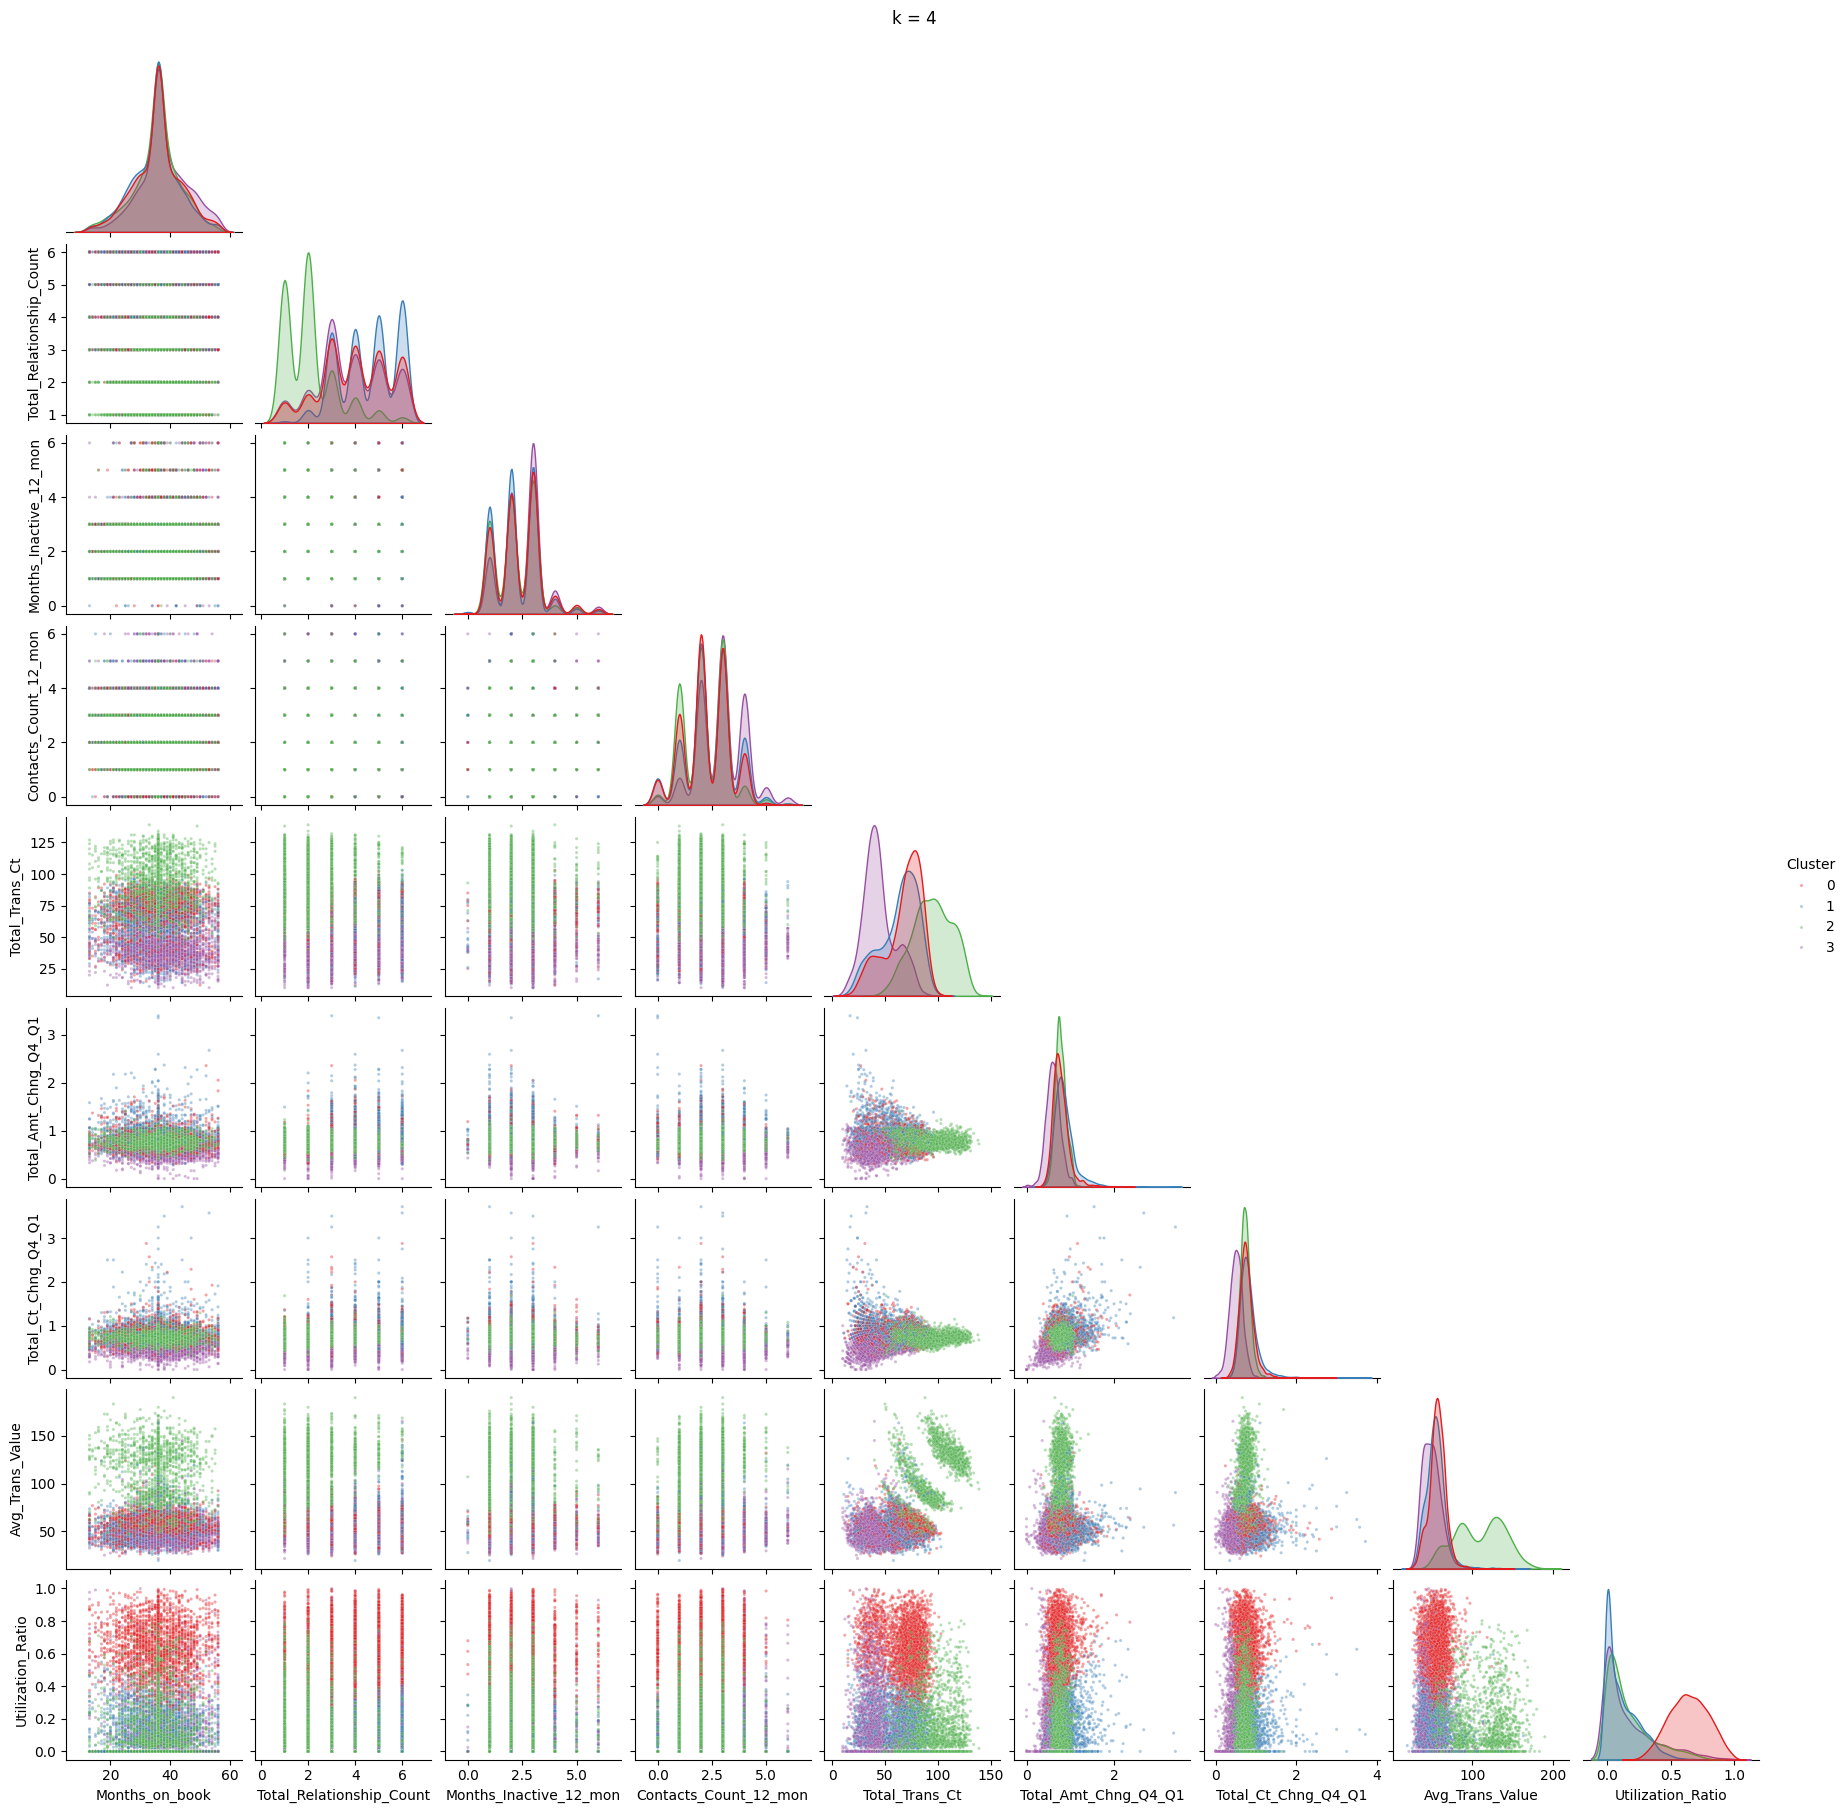

In [54]:
plot_cluster_pairs(COMPARE_K[1])

`Utilization_Ratio` separates the clusters most clearly in this solution. Cluster 0 lies almost entirely between 0.4 and 1, while clusters 1, 2 and 3 stay close to 0, so in every scatter plot with the utilization ratio, cluster 0 forms its own band at the top. `Avg_Trans_Value` and `Total_Relationship_Count` set cluster 2 apart, with the highest amounts per purchase and mostly one or two products. `Total_Trans_Ct`, the two Q4/Q1 ratios and `Contacts_Count_12_mon` separate cluster 3, which has the fewest transactions, a drop from Q1 to Q4 and more contacts with the bank. Clusters 0 and 1 overlap strongly in all features except the utilization ratio. `Months_on_book` and `Months_Inactive_12_mon` again hardly separate the clusters.

Compared with the smaller solution, the main change is the new separation by utilization. The high spenders and the customers with the lowest activity form a cluster of their own in both solutions. In the smaller solution, however, customers with a high utilization were mixed with customers who use almost none of their limit, which showed as two peaks of the utilization ratio within one cluster. Here they form a separate cluster. Which customers move between the clusters is shown in the comparison table below.

### Cluster centres

The centres are the mean values of the prepared features in each cluster. Because the features are standardized, the values are in standard deviations from the mean of all customers, so they show directly which features differ most between the clusters.

In [55]:
def cluster_centres(k_values):
    return pd.concat({
        f"k = {k}": X.groupby(df[f"Cluster_k{k}"]).mean().T.rename(columns=lambda c: f"Cluster {c}")
        for k in k_values
    }, axis=1).round(2)


display(cluster_centres(COMPARE_K))

k = 3                         k = 4            \
                         Cluster 0 Cluster 1 Cluster 2 Cluster 0 Cluster 1   
Months_on_book                0.16     -0.11     -0.03     -0.03     -0.11   
Total_Relationship_Count      0.11      0.41     -1.13      0.12      0.47   
Months_Inactive_12_mon        0.17     -0.09     -0.07      0.02     -0.11   
Contacts_Count_12_mon         0.45     -0.23     -0.26     -0.18     -0.04   
Total_Trans_Ct               -0.70      0.03      1.15      0.11     -0.08   
Total_Amt_Chng_Q4_Q1         -0.60      0.43      0.06      0.07      0.46   
Total_Ct_Chng_Q4_Q1          -0.75      0.51      0.13      0.24      0.48   
Avg_Trans_Value              -0.51     -0.23      1.41     -0.16     -0.29   
Utilization_Ratio            -0.32      0.37     -0.30      1.32     -0.58   

                                              
                         Cluster 2 Cluster 3  
Months_on_book               -0.05      0.21  
Total_Relationship_Count     -1.13     -0.00  
Months_Inactive_12_mon       -0.09      0.19  
Contacts_Count_12_mon        -0.25      0.42  
Total_Trans_Ct                1.27     -0.87  
Total_Amt_Chng_Q4_Q1          0.11     -0.76  
Total_Ct_Chng_Q4_Q1           0.11     -0.98  
Avg_Trans_Value               1.67     -0.55  
Utilization_Ratio            -0.41     -0.39

The centres confirm what the pair plots show. In the solution with 3 clusters, the largest differences are in `Avg_Trans_Value` and `Total_Trans_Ct`, where cluster 2 lies well above the other two (1.41 and 1.15 standard deviations), and in `Total_Relationship_Count`, where the same cluster lies more than one standard deviation below the mean. The two Q4/Q1 ratios separate cluster 0, which lies clearly below the mean, from cluster 1 above it. The centres of `Utilization_Ratio` differ only moderately, because the two peaks of cluster 1 average out in its mean.

In the solution with 4 clusters, `Utilization_Ratio` has the largest difference of all: cluster 0 lies 1.32 standard deviations above the mean and cluster 1 0.58 below it. Apart from this, the centres of these two clusters are close to each other in every feature. The high spenders (cluster 2) and the customers with the lowest activity (cluster 3) have centres similar to their counterparts in the smaller solution, and the low activity of cluster 3 is even more pronounced, with the lowest centre in `Total_Ct_Chng_Q4_Q1` (-0.98).

In both solutions, the centres of `Months_on_book` and `Months_Inactive_12_mon` stay within 0.21 standard deviations of the mean, so these features play almost no role in the clustering.

### How the clusters of the two solutions correspond

The table shows how many customers of each cluster of the smaller solution end up in each cluster of the larger one.

In [56]:
def cluster_match(k_a, k_b):
    match = pd.crosstab(df[f"Cluster_k{k_a}"], df[f"Cluster_k{k_b}"])
    match.index = [f"k = {k_a}, cluster {i}" for i in match.index]
    match.columns = [f"k = {k_b}, cluster {j}" for j in match.columns]
    return match


display(cluster_match(*COMPARE_K))

,"k = 4, cluster 0","k = 4, cluster 1","k = 4, cluster 2","k = 4, cluster 3"
"k = 3, cluster 0",294,739,0,2450
"k = 3, cluster 1",2223,2413,2,2
"k = 3, cluster 2",191,146,1653,14


When the number of clusters grows from 3 to 4, the three original clusters change as follows:
- Cluster 2 stays almost unchanged and keeps its number. Only a few hundred of its customers move to other clusters.
- Cluster 0 also stays together and becomes cluster 3, but about 1,000 of its customers move to the new clusters 0 and 1.
- Cluster 1 is split almost in half between the new clusters 0 and 1.

The new clusters 0 and 1 are therefore formed mainly from the original cluster 1, together with the customers who left clusters 0 and 2. As the pair plots showed, they differ mainly in their utilization ratio.

### Profiles

The first table describes every cluster with the medians of the clustering features and of the profile variables in their original units, the share of customers without a balance, the churn rate and the size. The second table shows the share of each category of the categorical variables. Both solutions are placed side by side, and the last column shows the same values for all customers.

In [57]:
numeric_profile_cols = cluster_features + [
    "Customer_Age", "Dependent_count", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt", "Open_To_Buy",
]
category_cols = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]


def summarize(data):
    summary = data[numeric_profile_cols].median()
    summary["Zero balance (%)"] = data["Zero_Balance"].mean() * 100
    summary["Churn rate (%)"] = data["Churned"].mean() * 100
    summary["Customers"] = len(data)
    return summary


def category_shares(data):
    return pd.concat({col: data[col].value_counts(normalize=True, sort=False) * 100 for col in category_cols})


def compare_clusters(describe, k_values, decimals):
    table = pd.concat({
        f"k = {k}": pd.DataFrame({f"Cluster {c}": describe(group) for c, group in df.groupby(f"Cluster_k{k}")})
        for k in k_values
    }, axis=1)
    table[("All customers", "")] = describe(df)
    return table.round(decimals)


display(compare_clusters(summarize, COMPARE_K, decimals=2))
display(compare_clusters(category_shares, COMPARE_K, decimals=1))

k = 3                         k = 4            \
                         Cluster 0 Cluster 1 Cluster 2 Cluster 0 Cluster 1   
Months_on_book               36.00     36.00     36.00     36.00     36.00   
Total_Relationship_Count      4.00      5.00      2.00      4.00      5.00   
Months_Inactive_12_mon        3.00      2.00      2.00      2.00      2.00   
Contacts_Count_12_mon         3.00      2.00      2.00      2.00      2.00   
Total_Trans_Ct               45.00     69.50     90.00     72.00     67.00   
Total_Amt_Chng_Q4_Q1          0.63      0.80      0.75      0.74      0.81   
Total_Ct_Chng_Q4_Q1           0.55      0.78      0.72      0.74      0.78   
Avg_Trans_Value              49.54     55.12     97.99     56.31     53.66   
Utilization_Ratio             0.08      0.37      0.10      0.64      0.07   
Customer_Age                 48.00     45.00     46.00     46.00     45.00   
Dependent_count               2.00      2.00      2.00      2.00      2.00   
Credit_Limit               5600.00   3229.00   7562.00   2565.00   7236.00   
Total_Revolving_Bal         984.00   1407.50   1317.00   1655.00    933.00   
Total_Trans_Amt            2167.00   4019.50   8216.50   4239.50   3706.00   
Open_To_Buy                4618.00   1851.50   6309.50    837.00   6033.50   
Zero balance (%)             35.66     15.95     24.35      0.00     36.39   
Churn rate (%)               34.65      3.84     12.08      5.95      6.34   
Customers                  3483.00   4640.00   2004.00   2708.00   3298.00   

                                             All customers  
                         Cluster 2 Cluster 3                
Months_on_book               36.00     36.00         36.00  
Total_Relationship_Count      2.00      4.00          4.00  
Months_Inactive_12_mon        2.00      3.00          2.00  
Contacts_Count_12_mon         2.00      3.00          2.00  
Total_Trans_Ct               95.00     42.00         67.00  
Total_Amt_Chng_Q4_Q1          0.76      0.60          0.74  
Total_Ct_Chng_Q4_Q1           0.72      0.50          0.70  
Avg_Trans_Value             113.26     48.27         55.79  
Utilization_Ratio             0.10      0.08          0.18  
Customer_Age                 46.00     48.00         46.00  
Dependent_count               2.00      2.00          2.00  
Credit_Limit               9267.00   5827.50       4549.00  
Total_Revolving_Bal        1357.00    917.50       1276.00  
Total_Trans_Amt            8904.00   1989.00       3899.00  
Open_To_Buy                7897.00   4730.00       3474.00  
Zero balance (%)             22.48     36.42         24.39  
Churn rate (%)               13.11     42.17         16.07  
Customers                  1655.00   2466.00      10127.00

k = 3                         k = 4  \
                               Cluster 0 Cluster 1 Cluster 2 Cluster 0   
Gender          F                   46.4      60.0      47.9      74.8   
                M                   53.6      40.0      52.1      25.2   
Education_Level Uneducated          16.7      17.8      17.8      17.0   
                High School         22.8      23.9      23.3      24.7   
                College             11.5      12.0      11.8      11.8   
                Graduate            37.2      34.9      36.2      35.3   
                Post-Graduate        5.8       6.3       5.9       6.2   
                Doctorate            6.1       5.0       5.0       5.1   
Marital_Status  Divorced             6.8       8.0       7.1       7.2   
                Married             48.4      45.9      43.5      46.9   
                Single              38.0      39.1      40.3      39.0   
                Unknown              6.8       7.1       9.0       7.0   
Income_Category Less than $40K      37.2      47.7      36.6      63.5   
                $40K - $60K         16.9      19.4      18.1      20.4   
                $60K - $80K         16.3      13.0      15.5       8.1   
                $80K - $120K        20.3      15.0      21.2       6.1   
                $120K +              9.3       5.0       8.6       2.0   
Card_Category   Blue                94.1      96.6      83.6     100.0   
                Silver               5.2       2.9      12.0       0.0   
                Gold                 0.6       0.5       3.6       0.0   
                Platinum             0.1       0.0       0.8       0.0   

                                                             All customers  
                               Cluster 1 Cluster 2 Cluster 3                
Gender          F                   45.9      41.9      45.7          52.9  
                M                   54.1      58.1      54.3          47.1  
Education_Level Uneducated          18.1      17.6      16.9          17.4  
                High School         22.5      23.2      23.3          23.4  
                College             12.2      11.4      11.5          11.8  
                Graduate            35.5      36.5      37.0          36.0  
                Post-Graduate        6.3       6.3       5.5           6.1  
                Doctorate            5.4       5.1       5.8           5.4  
Marital_Status  Divorced             8.0       7.3       6.8           7.4  
                Married             44.4      43.2      50.3          46.3  
                Single              40.3      40.4      36.2          38.9  
                Unknown              7.3       9.1       6.7           7.4  
Income_Category Less than $40K      34.0      31.7      35.5          41.9  
                $40K - $60K         17.4      17.9      17.4          18.3  
                $60K - $80K         17.0      16.8      17.2          14.6  
                $80K - $120K        23.0      23.9      20.6          18.0  
                $120K +              8.6       9.7       9.3           7.2  
Card_Category   Blue                92.4      80.9      94.9          93.2  
                Silver               6.5      14.0       4.5           5.5  
                Gold                 1.0       4.2       0.5           1.1  
                Platinum             0.1       0.9       0.1           0.2

The two clusters that come out of the split use the card in almost the same way. Both make about 70 transactions a year with a similar amount per purchase, their spending changed similarly from Q1 to Q4, and only about 6% of their customers closed their account.

The difference lies in their credit. The cluster with high utilization has the lowest credit limits of all clusters, and its typical customer uses about two thirds of the limit. Every customer in this cluster carries a balance. The cluster with low utilization has limits almost three times as high, but its customers use very little of them, and more than a third carry no balance at all.

The profile variables, which were not used to build the clusters, point in the same direction. Three quarters of the customers with the high utilization are women, almost two thirds earn less than \$40K, and all of them hold a Blue card, while the cluster with the low utilization is much closer to the rest of the customers in gender and income. The two clusters therefore describe different types of customers: one uses a large part of a small limit, the other leaves most of a large limit unused. Their risk of leaving, however, is about the same.

The solution with 4 clusters is chosen. The silhouette score and the stability check could not decide between 3 and 4 clusters, so the decision is based on what the clusters mean, and here the larger solution gives a clearer picture in two ways.

First, it separates two different types of customers that the smaller solution mixed in one cluster. Customers who use a large part of a small limit and customers who leave most of a large limit unused differ in their credit and in their profile, even though they use the card similarly and leave equally rarely.

Second, the cluster with the lowest activity becomes more precise. In the larger solution, its more active part, about 1,000 customers, moves to the two new clusters. The customers who remain are those with the lowest activity, and 42% of them closed their account, compared with about 35% in the original cluster. For a bank that wants to find customers at risk of leaving, this cluster is the most important one, and with 4 clusters it marks them more precisely. The high spenders stay practically the same in both solutions.